## Analyse MFCC

Les 13 MFCC en entrée de la prédiction de la phrase suivante (sans plancher des dB, mis à l'échelle (0, 1) par un MinMax appris sur les chants d'entraînement). D'abord un chant choisi dans la liste : son spectrogramme et ses phrases, ses MFCC, leurs deltas et delta-deltas en cartes de chaleur (deltas centrés sur 9 trames, ceux du cache des features, ou vers l'arrière : ceux de la trame 4 trames plus tôt, comme dans l'ablation `outputs/canary/ablation_deltas_leak`), puis les trois d'un coefficient choisi le long du chant. Le bouton `features` montre ces valeurs mises à l'échelle (l'entrée) ou brutes (celles du cache, avant le MinMax). Ensuite leurs amplitudes sur les chants d'entraînement : étendue et dispersion de chaque coefficient avant la mise à l'échelle (tableau), boîtes à moustaches avant et après, et des deltas et delta-deltas, dans les phrases et entre elles, et MFCC moyens de chaque étiquette de phrase, relativement à l'ensemble des trames chantées.

In [1]:
import pickle

import ipywidgets as widgets
import librosa
import librosa.display
import numpy as np
import soundfile as sf
from IPython.display import display
from matplotlib.colors import to_rgb
from matplotlib.figure import Figure

from canary.common import NO_FLOOR_FEATURES_CACHE, load_dataset, phrase_colors as colors_of_phrases
from canary.datasets.songs import download_canary_if_needed

N_MFCC = 13  # static MFCC (the cached features also have their deltas and delta-deltas, centered on 9 frames)
DELTA_LAG = 4  # backward deltas: those of the frame 4 frames earlier (the ablation outputs/canary/ablation_deltas_leak)

# the input of the next-phrase prediction: MFCC without the floor of the dB, MinMax-scaled (0, 1) on the train songs
mfcc_songs, mfcc_train_songs, mfcc_test_songs, mfcc_frame = load_dataset(top_db=None)
with open(NO_FLOOR_FEATURES_CACHE, "rb") as f:  # (the same features before their scaling: those of the cache)
    raw_songs = pickle.load(f)[0]
_, audio_dir = download_canary_if_needed()
wav_paths = {path.name: path for path in audio_dir.rglob("*.wav")}
phrase_colors = colors_of_phrases()


def show_mfcc(change=None):
    """Spectrogram of the chosen song with its phrases, its MFCC, their deltas and delta-deltas (heat maps), and the
    three of the chosen coefficient along the song, raw or scaled."""
    wave, k, scale = mfcc_song_choice.value, mfcc_coefficient.value, mfcc_scale_choice.value
    song = mfcc_songs[wave]
    # MFCC, deltas, delta-deltas: scaled (the input) or raw (the cache)
    features = (song if scale == "scaled" else raw_songs[wave])["mfcc"][:, :3 * N_MFCC].astype(np.float64)
    if mfcc_delta_choice.value == "backward":  # the deltas of the frame DELTA_LAG frames earlier (none before)
        features[:, N_MFCC:] = np.vstack([np.full((DELTA_LAG, 2 * N_MFCC), np.nan), features[:-DELTA_LAG, N_MFCC:]])
    groups = {"MFCC": features[:, :N_MFCC], "Δ": features[:, N_MFCC:2 * N_MFCC], "ΔΔ": features[:, 2 * N_MFCC:]}
    times = np.arange(len(features)) * mfcc_frame
    audio, rate = sf.read(wav_paths[wave], dtype="float32", always_2d=True)
    audio = audio.mean(axis=1)

    fig = Figure(figsize=(18, 11))  # (a figure of its own, not pyplot's current one)
    axes = fig.subplots(5, 1, sharex=True, gridspec_kw=dict(height_ratios=[3, 2.2, 2.2, 2.2, 2]))
    fig.subplots_adjust(left=0.05, right=0.93, top=0.96, bottom=0.05, hspace=0.1)
    S = librosa.amplitude_to_db(np.abs(librosa.stft(audio, n_fft=1024, hop_length=256)), ref=np.max)
    librosa.display.specshow(S, sr=rate, hop_length=256, x_axis="time", y_axis="hz", ax=axes[0], cmap="magma")
    axes[0].set_ylim(0, 10000)
    for start, end, label in song["phrases"]:  # the phrases on a band at the top (the label of the wide ones)
        axes[0].axvspan(start, end, ymin=0.9, ymax=1, color=phrase_colors.get(label, "grey"))
        if end - start > 0.008 * times[-1]:
            dark = np.dot(to_rgb(phrase_colors.get(label, "grey")), [0.299, 0.587, 0.114]) < 0.5  # (white label)
            axes[0].text((start + end) / 2, 9500, label, ha="center", va="center", fontsize=7,
                         color="white" if dark else "black")
    axes[0].set_xlabel("")
    axes[0].set_title(f"{wave} ({'train' if wave in set(mfcc_train_songs) else 'test'}), {scale} features, "
                      f"{mfcc_delta_choice.value} deltas", loc="left", fontsize=11)

    for ax, (name, values) in zip(axes[1:4], groups.items()):  # (colors: 1st to 99th percentile of the song)
        low, high = np.nanpercentile(values, [1, 99])
        image = ax.imshow(values.T, aspect="auto", origin="lower", cmap="viridis", vmin=low, vmax=high,
                          interpolation="nearest", extent=(0, len(values) * mfcc_frame, -0.5, N_MFCC - 0.5))
        ax.set_yticks(range(0, N_MFCC, 2))
        ax.set_ylabel(name)
        ax.axhspan(k - 0.5, k + 0.5, xmin=-0.006, xmax=0, color="#e53935", clip_on=False)  # (the chosen coefficient)
        fig.colorbar(image, cax=ax.inset_axes([1.005, 0, 0.008, 1]), label=f"{scale} value")

    for (name, values), color in zip(groups.items(), ("#1a1a1a", "#1f77b4", "#ff7f0e")):
        axes[4].plot(times, values[:, k], color=color, linewidth=0.7, label=f"{name} c{k}")
    axes[4].set_ylabel(f"{scale} value")
    axes[4].set_xlabel("time in the song (s)")
    axes[4].legend(loc="upper left", bbox_to_anchor=(1.005, 1.02), fontsize=8, frameon=False)
    axes[4].set_xlim(0, len(features) * mfcc_frame)
    with mfcc_view:
        mfcc_view.clear_output(wait=True)
        display(fig)


mfcc_song_choice = widgets.Dropdown(
    options=[(f"{w} (test)", w) for w in mfcc_test_songs] + [(f"{w} (train)", w) for w in mfcc_train_songs],
    description="song", layout=widgets.Layout(width="560px"))
mfcc_coefficient = widgets.Dropdown(options=[(f"c{k}", k) for k in range(N_MFCC)], value=1, description="coefficient",
                                    layout=widgets.Layout(width="200px"))
mfcc_delta_choice = widgets.ToggleButtons(options=["centered", "backward"], description="deltas",
                                          style=widgets.ToggleButtonsStyle(button_width="90px"))
mfcc_scale_choice = widgets.ToggleButtons(options=["scaled", "raw"], description="features",
                                          style=widgets.ToggleButtonsStyle(button_width="80px"))
mfcc_view = widgets.Output()
for choice in (mfcc_song_choice, mfcc_coefficient, mfcc_delta_choice, mfcc_scale_choice):
    choice.observe(show_mfcc, names="value")
show_mfcc()
display(widgets.VBox([widgets.HBox([mfcc_song_choice, mfcc_coefficient, mfcc_delta_choice, mfcc_scale_choice]),
                      mfcc_view]))

# Exploration des chants de canari (marron1)

Chants du canari marron1 ([M1-2016-spring](https://zenodo.org/records/6521932) : 459 chants annotés, enregistrés à 44,1 kHz), découpés en phrases (segments consécutifs de même étiquette fusionnés, SIL et TRASH ignorés, cris compris), et la prédiction de la phrase suivante (`canary.next_phrase_prediction`) :

1. **Statistiques de base** : un chant annoté, les étiquettes, la syntaxe (transitions entre phrases), et les instances de la tâche Canary de hag ;
2. **Découpage des chants** en entraînement (367) et test (92), et ses transitions ;
3. **Prédiction de la phrase suivante** : sorties du readout le long d'un chant de test, matrice de confusion ;
4. **Espace des phrases** : ACP, UMAP et t-SNE en 3D des MFCC des phrases (avec écoute des extraits), trajectoire d'un chant dans l'UMAP ou le t-SNE, phrases atypiques (outliers).

Les sections sont indépendantes, sauf quand une cellule demande d'exécuter la précédente. Prérequis : les études de la prédiction de la phrase suivante (`outputs/canary/studies/`, à copier depuis PlaFRIM), les caches de MFCC (`canary/datasets/Canary/boundary_features_*.pkl`, créés au premier chargement) ; après une modification du code de `hag` ou de `canary`, redémarrer le noyau.

## Statistiques de base

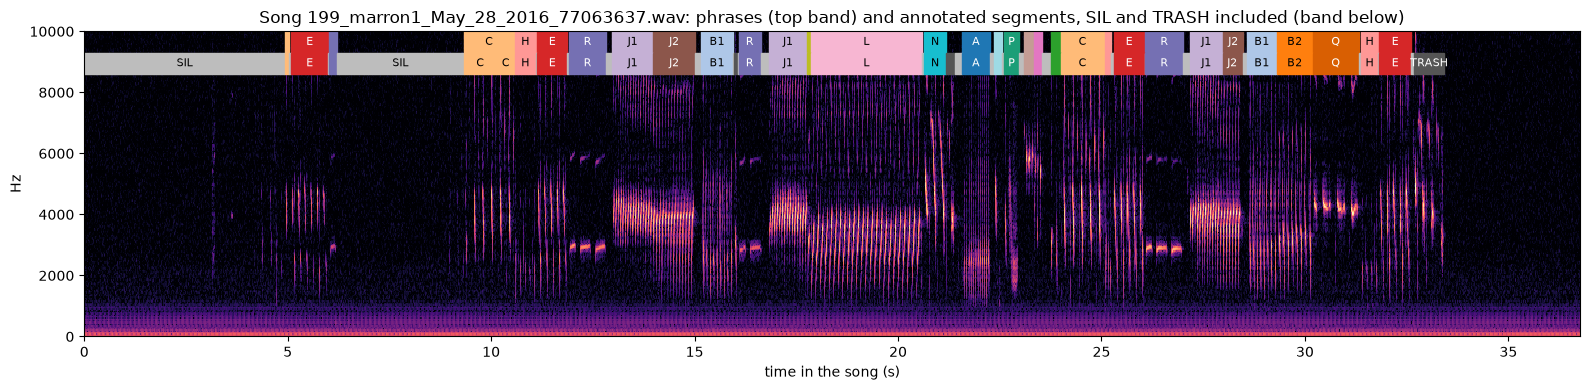

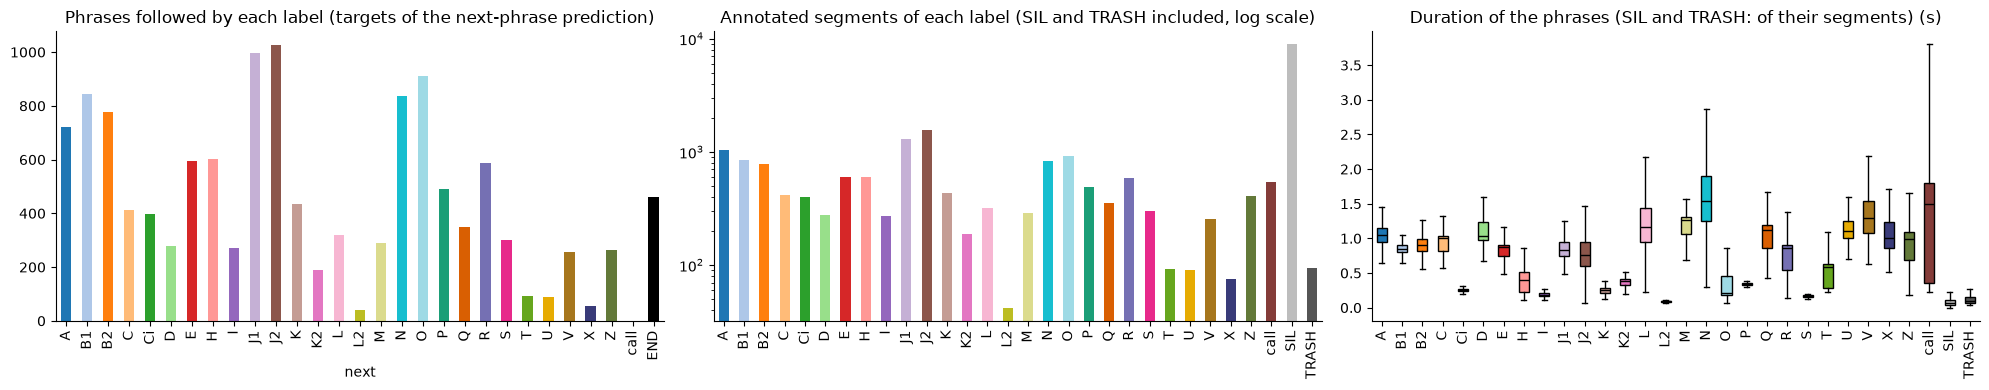

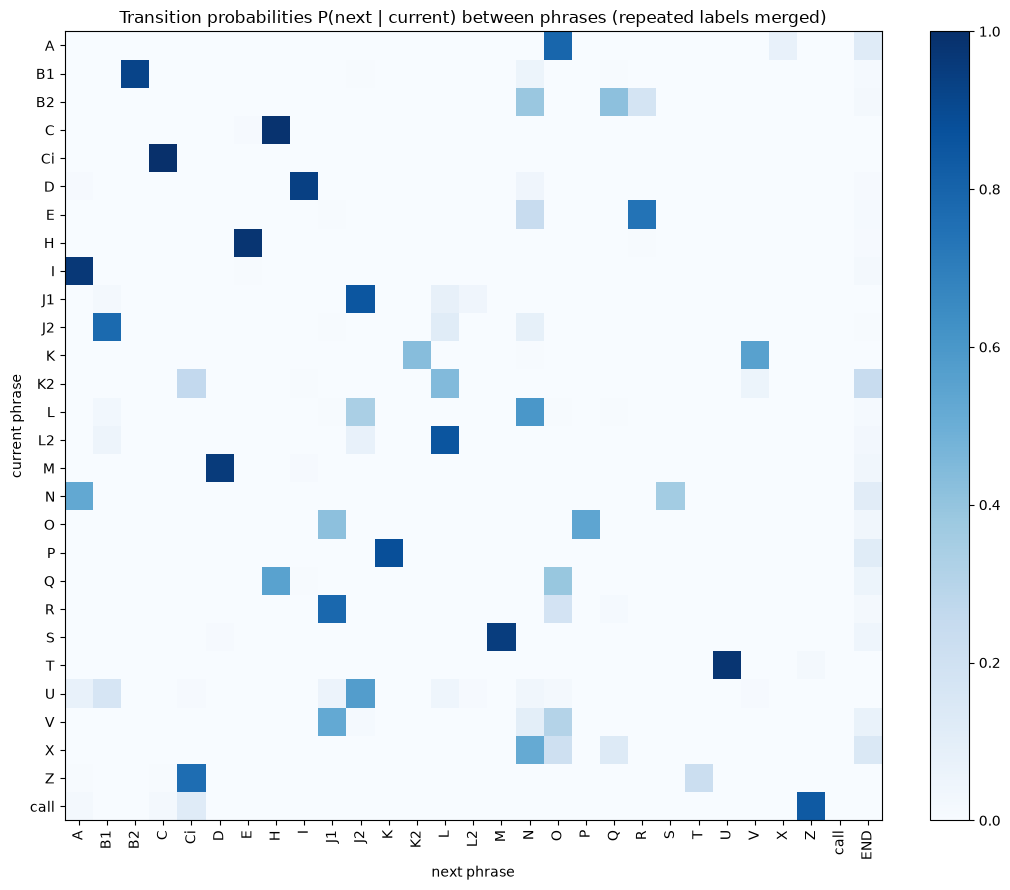

12887 phrases in 459 songs
Most-frequent-successor accuracy (knowing only the current label): 0.751
Majority-class accuracy: 0.080


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf

from matplotlib.colors import to_rgb

from canary.datasets.songs import download_canary_if_needed, build_phrase_sequences, song_phrases
from canary.common import phrase_colors as colors_of_phrases

SONG = None  # song of the spectrogram, None for the one with the longest TRASH segments in all
SEGMENT_COLORS = {"SIL": "#bdbdbd", "TRASH": "#555555"}  # (the annotated segments of the band below the phrases)

annotations_dir, audio_dir = download_canary_if_needed()
annotations = pd.concat([pd.read_csv(f, index_col=0) for f in sorted(annotations_dir.rglob("*.csv"))])
# one row per phrase of each song (consecutive segments of the same label merged, as in the next-phrase prediction;
# SIL and TRASH ignored, the calls are phrases): current phrase -> next phrase, END after the last phrase of the song
pairs = build_phrase_sequences(annotations, merge_repeats=True, end_label="END")
labels = sorted(set(pairs["current"]))
colors = colors_of_phrases()  # (a distinct color for each phrase, the same in all the cells)

# 1. One song: spectrogram with its phrases (top band, SIL and TRASH ignored) and its annotated segments (band below,
# SIL and TRASH in greys), their label when they are wide enough to be read
trash = annotations[annotations["syll"] == "TRASH"]
wave = SONG or (trash["end"] - trash["start"]).groupby(trash["wave"]).sum().idxmax()
audio, sr = sf.read(next(audio_dir.rglob(wave)), dtype="float32")
S = librosa.amplitude_to_db(np.abs(librosa.stft(audio, n_fft=1024, hop_length=256)), ref=np.max)

fig, ax = plt.subplots(figsize=(16, 4))
librosa.display.specshow(S, sr=sr, hop_length=256, x_axis="time", y_axis="hz", ax=ax, cmap="magma")
ax.set_ylim(0, 10000)
segments = annotations.loc[annotations["wave"] == wave, ["start", "end", "syll"]].itertuples(index=False)
for spans, low, palette in ((song_phrases(annotations, wave, ("SIL", "TRASH")), 0.93, colors),
                            (segments, 0.86, {**colors, **SEGMENT_COLORS})):
    for start, end, label in spans:
        ax.axvspan(start, end, ymin=low, ymax=low + 0.07, color=palette.get(label, "grey"))
        if end - start > 0.01 * len(audio) / sr:
            ax.text((start + end) / 2, (low + 0.035) * 10000, label, ha="center", va="center", fontsize=8,
                    color="white" if np.dot(to_rgb(palette.get(label, "grey")), [0.299, 0.587, 0.114]) < 0.5
                    else "black")
ax.set_xlabel("time in the song (s)")
ax.set_title(f"Song {wave}: phrases (top band) and annotated segments, SIL and TRASH included (band below)")
plt.tight_layout()
plt.show()

# 2. Number of phrases followed by each label, number of annotated segments of each label (SIL and TRASH included),
# and duration of the phrases of each label (SIL and TRASH: of their segments)
durations = pairs.assign(duration=pairs["end"] - pairs["start"])
ignored = [label for label in SEGMENT_COLORS if label in set(annotations["syll"])]
palette = {**colors, **SEGMENT_COLORS}
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 4))
pairs["next"].value_counts().reindex(labels + ["END"]).plot.bar(ax=ax1, color=[colors[l] for l in labels + ["END"]])
ax1.set_title("Phrases followed by each label (targets of the next-phrase prediction)")
annotations["syll"].value_counts().reindex(labels + ignored, fill_value=0).plot.bar(
    ax=ax2, color=[palette[l] for l in labels + ignored], logy=True)  # (SIL: many more segments)
ax2.set_title("Annotated segments of each label (SIL and TRASH included, log scale)")
segment_durations = annotations["end"] - annotations["start"]
boxes = ax3.boxplot([durations.loc[durations["current"] == l, "duration"] for l in labels]
                    + [segment_durations[annotations["syll"] == l] for l in ignored], showfliers=False,
                    patch_artist=True, medianprops=dict(color="black"))
for box, label in zip(boxes["boxes"], labels + ignored):
    box.set_facecolor(palette[label])
ax3.set_xticks(range(1, len(labels + ignored) + 1), labels + ignored, rotation=90)
ax3.set_title("Duration of the phrases (SIL and TRASH: of their segments) (s)")
for ax in (ax1, ax2, ax3):
    ax.spines[["top", "right"]].set_visible(False)
ax2.set_xlabel("")
plt.tight_layout()
plt.show()

# 3. Song syntax: P(next | current) transition matrix between phrases (no transition of a phrase to itself, the
# repeated labels being merged), END after the last phrase of each song
transitions = pd.crosstab(pairs["current"], pairs["next"], normalize="index").reindex(
    index=labels, columns=labels + ["END"], fill_value=0)
fig, ax = plt.subplots(figsize=(10.5, 9))
im = ax.imshow(transitions, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(labels) + 1), labels + ["END"], rotation=90)
ax.set_yticks(range(len(labels)), labels)
ax.set_xlabel("next phrase")
ax.set_ylabel("current phrase")
ax.set_title("Transition probabilities P(next | current) between phrases (repeated labels merged)")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

# References (all the songs, the labels known): always predict the most frequent successor of the current phrase,
# or the most frequent next phrase
best_next = pairs.groupby("current")["next"].agg(lambda s: s.value_counts().index[0])
baseline = (pairs["current"].map(best_next) == pairs["next"]).mean()
print(f"{len(pairs)} phrases in {pairs['wave'].nunique()} songs")
print(f"Most-frequent-successor accuracy (knowing only the current label): {baseline:.3f}")
print(f"Majority-class accuracy: {pairs['next'].value_counts(normalize=True).iloc[0]:.3f}")

### Instances de la tâche Canary de hag

La tâche Canary de hag (`load_canary_dataset`, la classification de la phrase suivante de ses benchmarks), différente de la prédiction de la phrase suivante de ce notebook : une instance par phrase (segments non fusionnés), son audio seul à 16 kHz, la cible étant l'étiquette suivante ; quelques exemples (signal, spectrogramme mel, entrée du réservoir : MFCC et deltas mis à l'échelle). Cette cellule charge l'audio de tous les chants (quelques minutes).

Number of songs = 459
Number of instances (train / test) = 11089 / 2765
Number of classes = 28
Using MFCC config: {'sr': 16000, 'n_mfcc': 13, 'win_length': 372, 'hop_length': 186, 'n_fft': 743, 'fmin': 500, 'fmax': 8000, 'lifter': 40, 'deltas': True}


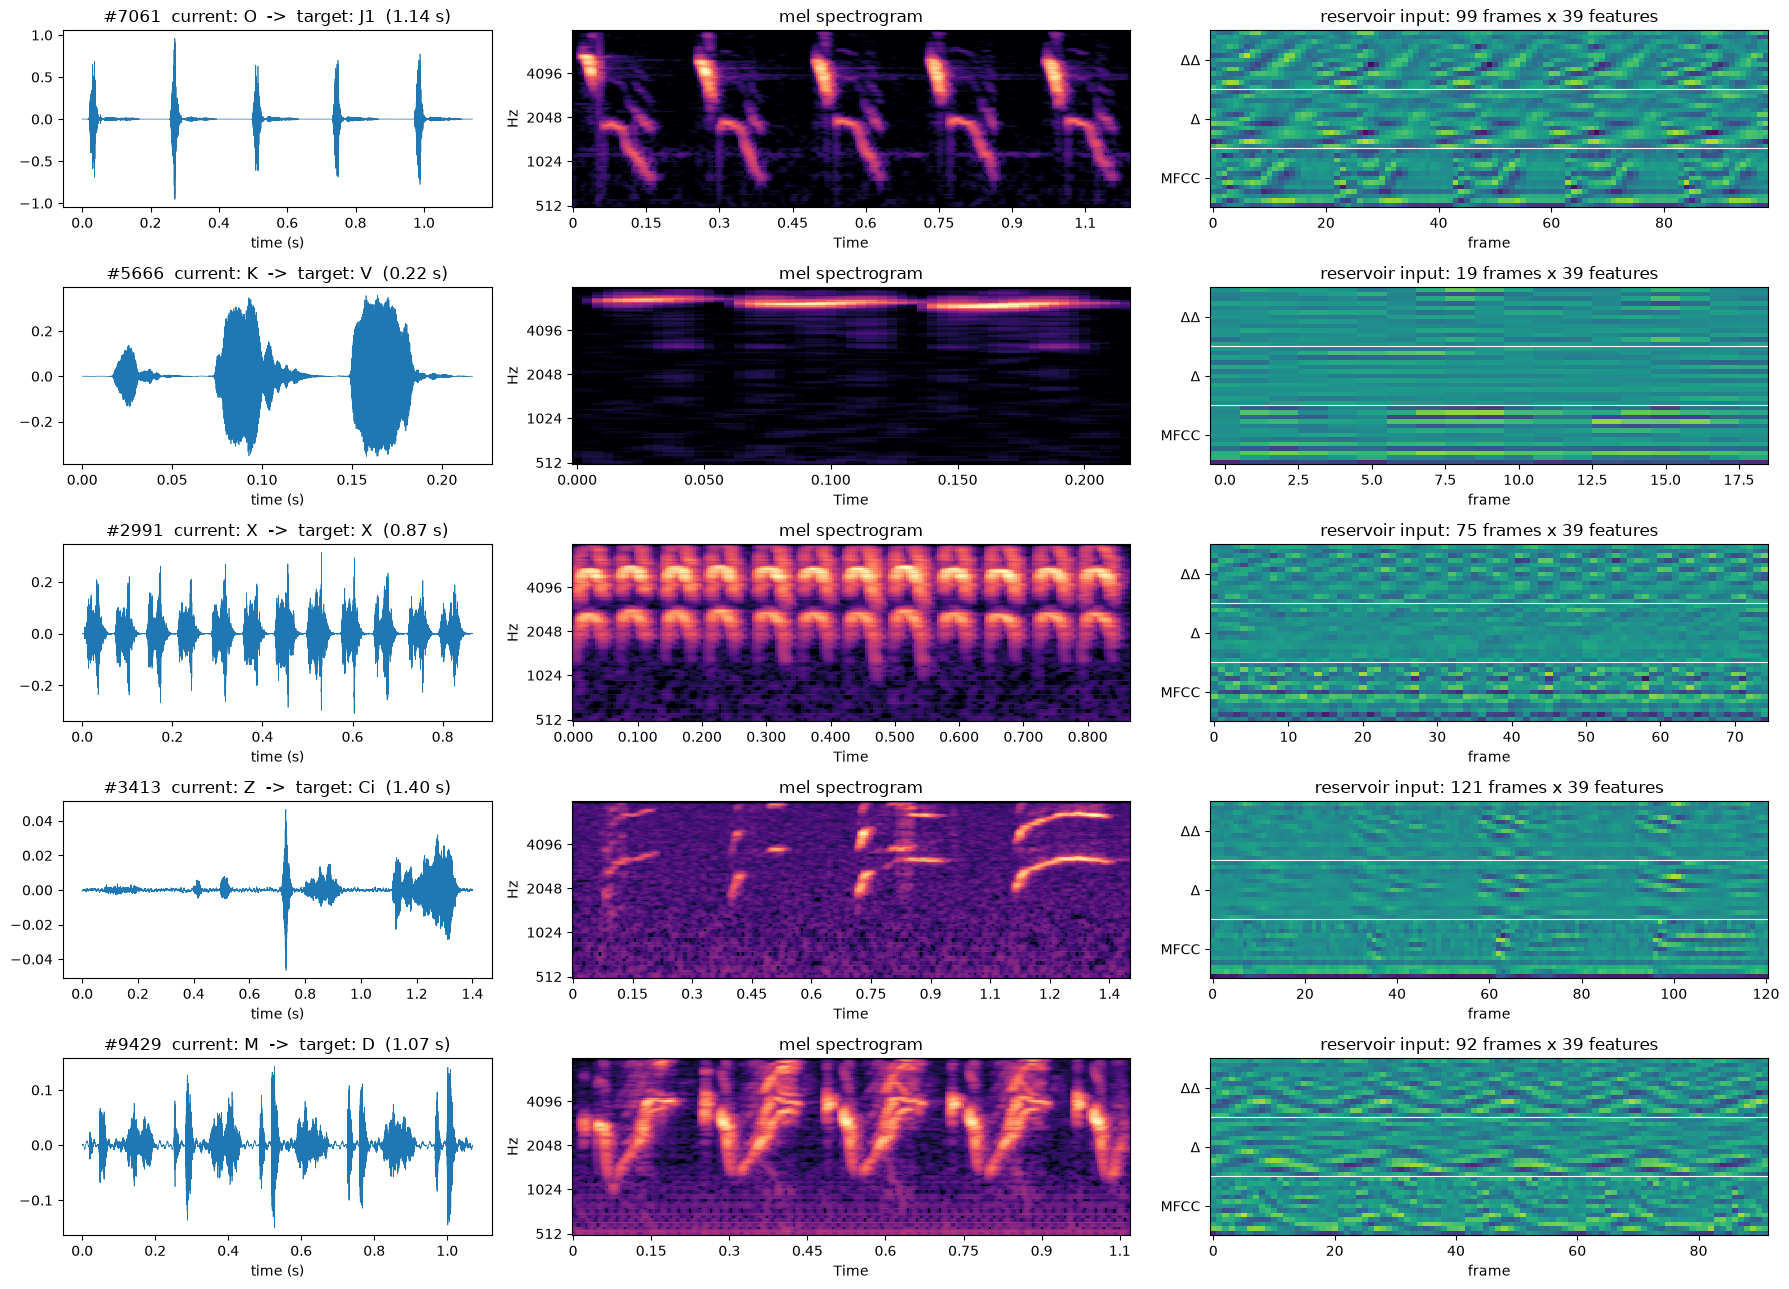

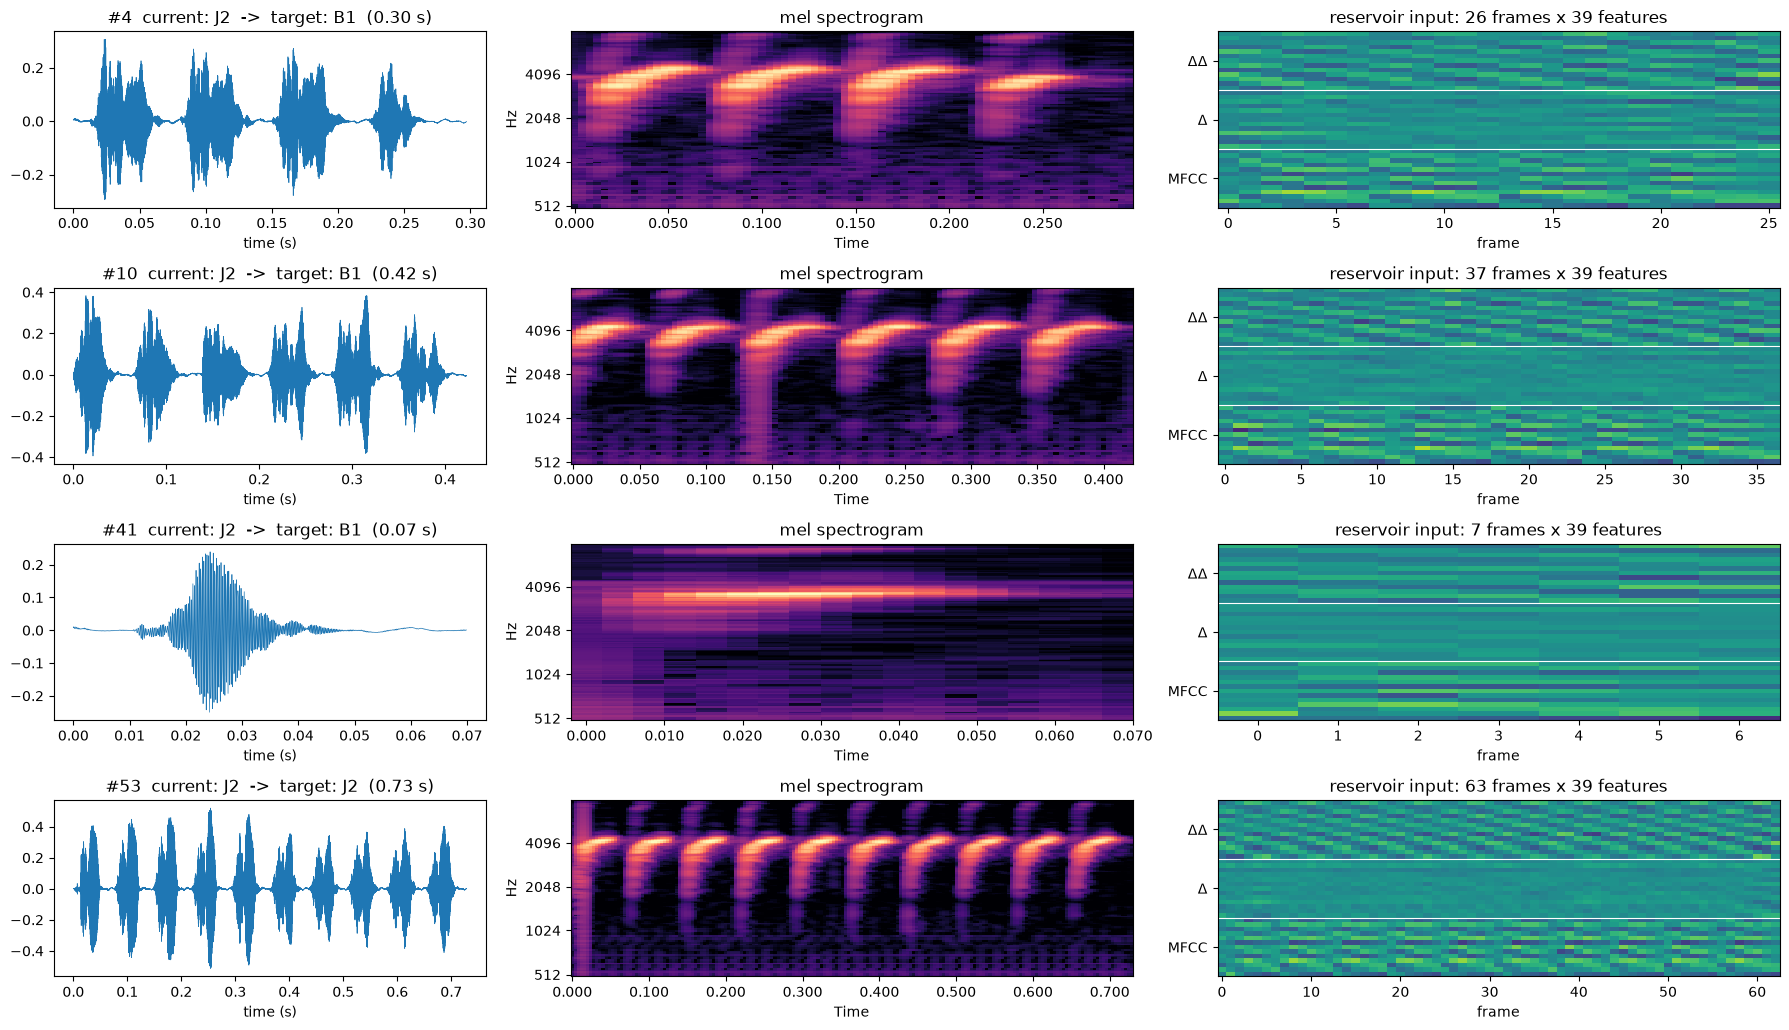

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
from sklearn.preprocessing import MinMaxScaler

from canary.datasets.songs import (load_canary_dataset, build_phrase_sequences, download_canary_if_needed,
                                   canary_mfcc_config, split_canary_songs)
from hag.datasets.spectral_decomposition import generate_multivariate_dataset
from hag.datasets.preprocessing import scale_data

sr, X_train, X_test, Y_train, Y_test, groups, classes = load_canary_dataset()

# Current phrase label of each training instance (the loader only returns the target = next label):
# rebuild the same pairs and the same song split, and check they are aligned with X_train
annotations_dir, _ = download_canary_if_needed()
annotations = pd.concat([pd.read_csv(f, index_col=0) for f in sorted(annotations_dir.rglob("*.csv"))])
pairs = build_phrase_sequences(annotations)
train_songs, _ = split_canary_songs(pairs["wave"])
train_pairs = pairs[pairs["wave"].isin(train_songs)].reset_index(drop=True)
assert (train_pairs["wave"].to_numpy() == groups).all() and (train_pairs["next"].to_numpy() == classes[Y_train.argmax(1)]).all()

# Model input: MFCC + deltas, MinMax-scaled on the training set (as in hpo_esn.py)
X_train_band = generate_multivariate_dataset(X_train, True, "mfcc", mfcc_config=canary_mfcc_config(sr), verbosity=0)
X_train_band, _, _ = scale_data(X_train_band, None, None, MinMaxScaler(feature_range=(0, 1)), True)

def show_examples(indices):
    fig, axes = plt.subplots(len(indices), 3, figsize=(18, 2.6 * len(indices)), gridspec_kw={"width_ratios": [1, 1.3, 1.3]})
    for row, i in zip(np.atleast_2d(axes), indices):
        audio = X_train[i].ravel()
        current, target = train_pairs.loc[i, "current"], train_pairs.loc[i, "next"]

        row[0].plot(np.arange(len(audio)) / sr, audio, lw=0.5)
        row[0].set_title(f"#{i}  current: {current}  ->  target: {target}  ({len(audio) / sr:.2f} s)")
        row[0].set_xlabel("time (s)")

        mel = librosa.power_to_db(librosa.feature.melspectrogram(y=audio, sr=sr, n_fft=512, hop_length=64, fmin=500, fmax=8000), ref=np.max)
        librosa.display.specshow(mel, sr=sr, hop_length=64, x_axis="time", y_axis="mel", fmin=500, fmax=8000, ax=row[1], cmap="magma")
        row[1].set_title("mel spectrogram")

        row[2].imshow(X_train_band[i].T, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
        row[2].axhline(12.5, color="w", lw=0.8)
        row[2].axhline(25.5, color="w", lw=0.8)
        row[2].set_yticks([6, 19, 32], ["MFCC", "Δ", "ΔΔ"])
        row[2].set_title(f"reservoir input: {X_train_band[i].shape[0]} frames x {X_train_band[i].shape[1]} features")
        row[2].set_xlabel("frame")
    plt.tight_layout()
    plt.show()

rng = np.random.default_rng(0)
show_examples(rng.choice(len(X_train), 5, replace=False))             # random examples
show_examples(train_pairs.index[train_pairs["current"] == "J2"][:4])  # one phrase type, its different targets

## Découpage des chants en entraînement et test

Découpage de la détection (`split_canary_songs` de `canary.datasets.songs` : `GroupShuffleSplit` par chant, 20 % des chants en test, les mêmes chants que la tâche Canary de hag) : tailles, classes de la phrase suivante (cris et `END` compris), longueur des chants et jours d'enregistrement.

,songs,phrases (with calls),phrases (without calls),calls,phrases per song,sung duration (min)
train,367,10316,10064,252,28.1,148.7
test,92,2571,2513,58,27.9,37.3


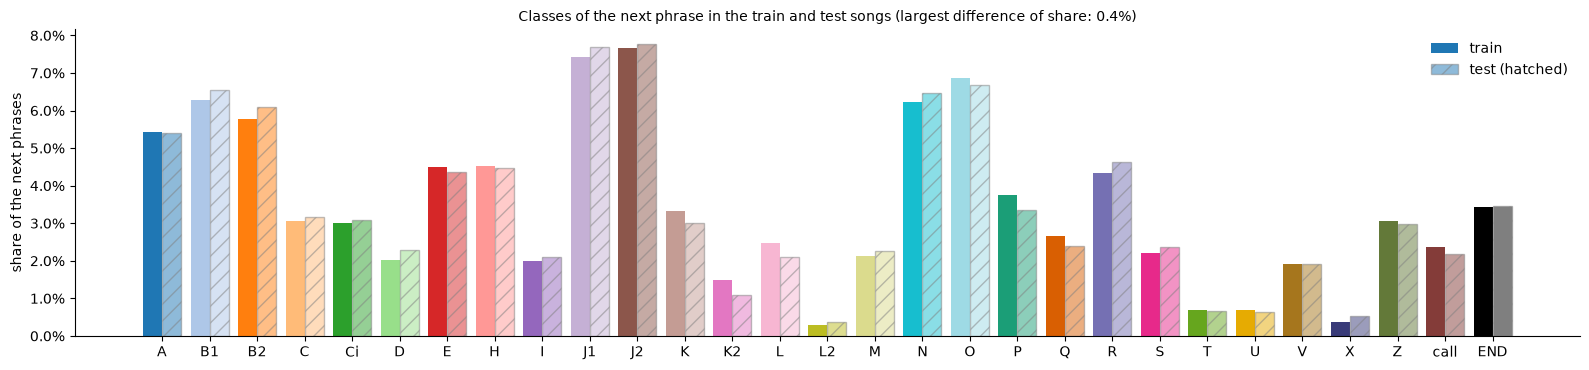

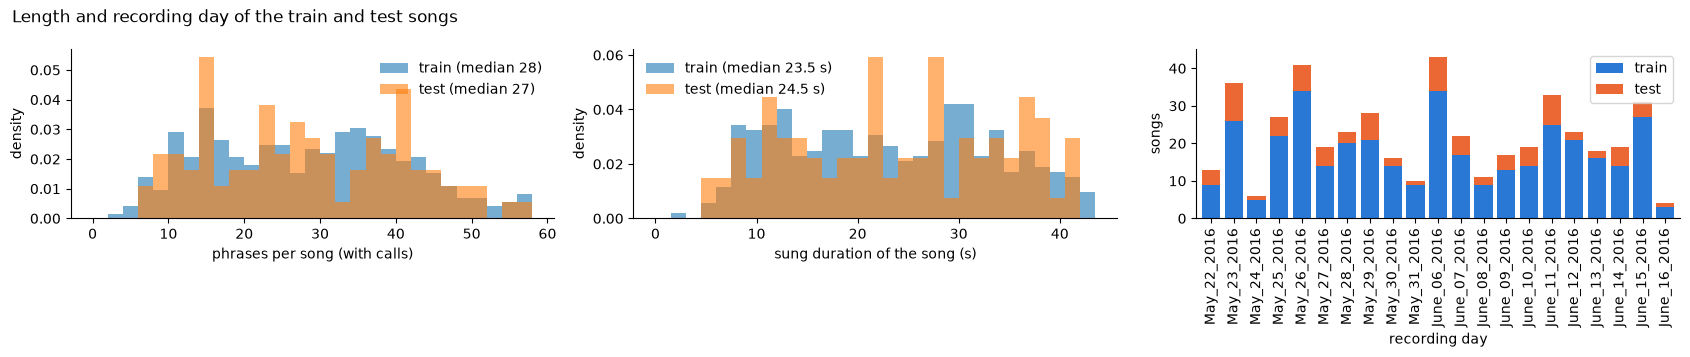

In [4]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from canary.datasets.songs import annotations_of_songs, build_phrase_sequences, song_phrases
from canary.common import load_dataset, phrase_colors as colors_of_phrases

# Train / test split of the songs of the detection (split_canary_songs: GroupShuffleSplit by song, 20 % of
# the songs in test, the same songs as the Canary task of hag)
_, train_songs, test_songs, _ = load_dataset()  # (cache of the MFCC: only the split is used here)
annotations = annotations_of_songs()
splits = {"train": train_songs, "test": test_songs}
phrases = {name: {w: song_phrases(annotations, w, ("SIL", "TRASH")) for w in waves} for name, waves in splits.items()}
pairs = build_phrase_sequences(annotations)
labels = sorted(set(pairs["current"]) | set(pairs["next"]))
colors = colors_of_phrases()  # (the colors of the phrases in all the cells, END in black)

# 1. Sizes of the splits (phrases: repeated labels merged, SIL and TRASH removed)
rows = []
for name, songs_phrases in phrases.items():
    rows.append({"songs": len(songs_phrases),
                 "phrases (with calls)": sum(len(p) for p in songs_phrases.values()),
                 "phrases (without calls)": sum(label != "call" for p in songs_phrases.values() for _, _, label in p),
                 "calls": sum(label == "call" for p in songs_phrases.values() for _, _, label in p),
                 "phrases per song": np.mean([len(p) for p in songs_phrases.values()]),
                 "sung duration (min)": sum(p[-1][1] - p[0][0] for p in songs_phrases.values()) / 60})
display(pd.DataFrame(rows, index=list(phrases)).round(1))

# 2. Classes of the next phrase (targets of the next-phrase prediction: each phrase, then END), share in each split
targets = {name: pd.Series([label for p in songs_phrases.values() for _, _, label in p] + ["END"] * len(songs_phrases))
           .value_counts(normalize=True) for name, songs_phrases in phrases.items()}
shares = pd.DataFrame(targets).fillna(0).reindex([label for label in labels + ["END"] if label in targets["train"].index
                                                  or label in targets["test"].index])
fig, ax = plt.subplots(figsize=(16, 3.8))
x = np.arange(len(shares))
ax.bar(x - 0.2, shares["train"], width=0.4, color=[colors[label] for label in shares.index], label="train")
ax.bar(x + 0.2, shares["test"], width=0.4, color=[colors[label] for label in shares.index], alpha=0.5, hatch="//",
       edgecolor="grey", label="test (hatched)")
ax.set_xticks(x, shares.index)
ax.set_ylabel("share of the next phrases")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title(f"Classes of the next phrase in the train and test songs (largest difference of share: "
             f"{(shares['train'] - shares['test']).abs().max():.1%})", fontsize=10)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# 3. Length of the songs (number of phrases, sung duration) and recording days of the songs
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for name, songs_phrases in phrases.items():
    n_phrases = [len(p) for p in songs_phrases.values()]
    durations = [p[-1][1] - p[0][0] for p in songs_phrases.values()]
    axes[0].hist(n_phrases, bins=np.arange(0, 60, 2), density=True, alpha=0.6, label=f"{name} (median {np.median(n_phrases):.0f})")
    axes[1].hist(durations, bins=np.arange(0, 45, 1.5), density=True, alpha=0.6, label=f"{name} (median {np.median(durations):.1f} s)")
axes[0].set_xlabel("phrases per song (with calls)")
axes[1].set_xlabel("sung duration of the song (s)")
days = pd.DataFrame({name: pd.Series([re.search(r"marron1_(\w+?_\d+_\d{4})_", w).group(1) for w in waves]).value_counts()
                     for name, waves in splits.items()}).fillna(0).astype(int)
days = days.loc[sorted(days.index, key=lambda d: pd.to_datetime(d, format="%B_%d_%Y"))]
days.plot.bar(ax=axes[2], stacked=True, color=["#2a78d6", "#eb6834"], width=0.8)
axes[2].set_xlabel("recording day")
axes[2].set_ylabel("songs")
for ax in axes[:2]:
    ax.set_ylabel("density")
    ax.legend(frameon=False)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Length and recording day of the train and test songs", x=0.01, ha="left")
plt.tight_layout()
plt.show()

### Transitions des chants d'entraînement et de test

Le découpage garde-t-il les statistiques de transitions entre phrases (phrases fusionnées, cris compris, `END` après la dernière phrase de chaque chant) ? Pour chaque phrase courante, distance en variation totale (TVD : 0, distributions identiques ; 1, disjointes) entre les distributions de sa phrase suivante dans les chants d'entraînement et de test, comparée à celle de `NB_RANDOM_SPLITS` découpages aléatoires par chant de même taille (`GroupShuffleSplit`, 20 % des chants en test) : la part des découpages aléatoires qui font au moins aussi mal dit si l'écart est plus grand que ce qu'on attend du hasard (peu de transitions en test : grands écarts attendus).

Mean TVD (weighted by the test transitions): our split 0.047, random splits 0.047 ± 0.006 (51 % of them at least as large)


,train transitions,test transitions,TVD,random median TVD,random splits at least as large,main next (train),main next (test),END (train),END (test)
U,74,17,0.304,0.231,18%,J2 0.61,J2 0.41,0.00,0.00
X,40,14,0.186,0.210,61%,N 0.47,N 0.64,0.15,0.14
L2,32,10,0.125,0.156,68%,L 0.84,L 0.90,0.03,0.00
B2,616,162,0.111,0.051,2%,Q 0.44,N 0.44,0.02,0.01
K,356,80,0.090,0.048,18%,V 0.54,V 0.61,0.00,0.00
call,252,58,0.088,0.054,15%,Z 0.85,Z 0.78,0.00,0.00
K2,160,29,0.079,0.119,79%,L 0.45,L 0.41,0.24,0.21
V,205,51,0.073,0.099,72%,J1 0.52,J1 0.53,0.07,0.06
A,579,144,0.062,0.045,22%,O 0.80,O 0.75,0.12,0.14
L,265,56,0.057,0.081,78%,N 0.59,N 0.62,0.01,0.02


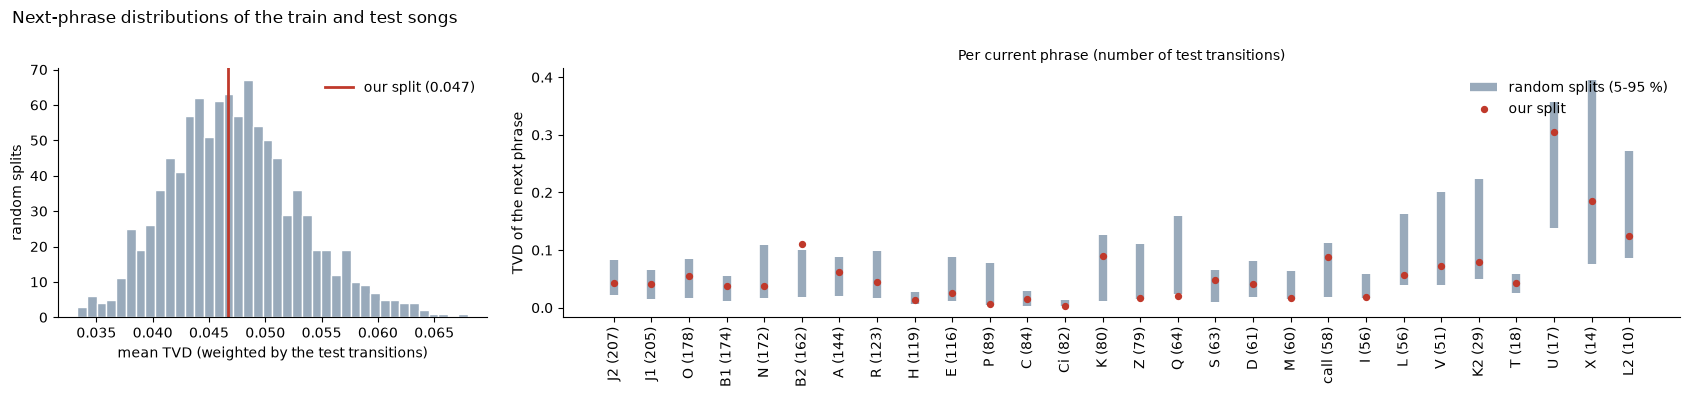

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit

from canary.datasets.songs import annotations_of_songs, build_phrase_sequences, split_canary_songs

NB_RANDOM_SPLITS = 1000

# transitions between phrases (repeated labels merged, calls included, END after the last phrase) of each song
pairs = build_phrase_sequences(annotations_of_songs(), merge_repeats=True, end_label="END")
train_songs, test_songs = split_canary_songs(pairs["wave"])
waves = np.array(sorted(set(pairs["wave"])))
current_labels = sorted(set(pairs["current"]))
next_labels = sorted(set(pairs["next"]) - {"END"}) + ["END"]
index = {"wave": {w: i for i, w in enumerate(waves)}, "current": {l: i for i, l in enumerate(current_labels)},
         "next": {l: i for i, l in enumerate(next_labels)}}
counts = np.zeros((len(waves), len(current_labels), len(next_labels)))
np.add.at(counts, tuple(pairs[column].map(index[column]).to_numpy() for column in ("wave", "current", "next")), 1)


def distances(test_mask):
    """TVD between the train and test next-phrase distributions of each current phrase, its number of test
    transitions, and the mean TVD weighted by them."""
    train, test = counts[~test_mask].sum(axis=0), counts[test_mask].sum(axis=0)
    n_test = test.sum(axis=1)
    tvd = 0.5 * np.abs(train / np.maximum(train.sum(axis=1, keepdims=True), 1)
                       - test / np.maximum(n_test[:, None], 1)).sum(axis=1)
    return tvd, n_test, (tvd * n_test).sum() / n_test.sum()


observed_mask = np.isin(waves, test_songs)
tvd, n_test, observed = distances(observed_mask)
random_tvd, random_mean = [], []
for _, test_index in GroupShuffleSplit(n_splits=NB_RANDOM_SPLITS, test_size=0.2, random_state=1).split(waves, groups=waves):
    mask = np.zeros(len(waves), dtype=bool)
    mask[test_index] = True
    split_tvd, split_n_test, split_mean = distances(mask)
    random_tvd.append(np.where(split_n_test > 0, split_tvd, np.nan))
    random_mean.append(split_mean)
random_tvd, random_mean = np.array(random_tvd), np.array(random_mean)
print(f"Mean TVD (weighted by the test transitions): our split {observed:.3f}, random splits {random_mean.mean():.3f} "
      f"± {random_mean.std():.3f} ({100 * np.mean(random_mean >= observed):.0f} % of them at least as large)")

# per current phrase
train_counts, test_counts = counts[~observed_mask].sum(axis=0), counts[observed_mask].sum(axis=0)
train_p = train_counts / train_counts.sum(axis=1, keepdims=True)
test_p = test_counts / np.maximum(test_counts.sum(axis=1, keepdims=True), 1)
end = next_labels.index("END")
table = pd.DataFrame({
    "train transitions": train_counts.sum(axis=1).astype(int), "test transitions": n_test.astype(int), "TVD": tvd,
    "random median TVD": np.nanmedian(random_tvd, axis=0),
    "random splits at least as large": np.nanmean(random_tvd >= tvd, axis=0),
    "main next (train)": [f"{next_labels[k]} {train_p[i, k]:.2f}" for i, k in enumerate(train_p.argmax(axis=1))],
    "main next (test)": [f"{next_labels[k]} {test_p[i, k]:.2f}" for i, k in enumerate(test_p.argmax(axis=1))],
    "END (train)": train_p[:, end], "END (test)": test_p[:, end]}, index=current_labels).sort_values("TVD", ascending=False)
display(table.style.format({"TVD": "{:.3f}", "random median TVD": "{:.3f}", "random splits at least as large": "{:.0%}",
                            "END (train)": "{:.2f}", "END (test)": "{:.2f}"})
        .apply(lambda row: ["background-color: #fde2e1" if row["random splits at least as large"] < 0.05 else ""
                            for _ in row], axis=1))

# mean TVD of the random splits, and TVD of each phrase within the 5-95 % range of the random splits
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 4), gridspec_kw=dict(width_ratios=[1, 2.6]))
ax1.hist(random_mean, bins=40, color="#9ab", edgecolor="white")
ax1.axvline(observed, color="#c0392b", linewidth=2, label=f"our split ({observed:.3f})")
ax1.set_xlabel("mean TVD (weighted by the test transitions)")
ax1.set_ylabel("random splits")
ax1.legend(frameon=False)
order = np.argsort(-n_test)
x = np.arange(len(order))
low, high = np.nanpercentile(random_tvd[:, order], [5, 95], axis=0)
ax2.vlines(x, low, high, color="#9ab", linewidth=6, label="random splits (5-95 %)")
ax2.scatter(x, tvd[order], color="#c0392b", zorder=3, s=18, label="our split")
ax2.set_xticks(x, [f"{current_labels[i]} ({int(n_test[i])})" for i in order], rotation=90)
ax2.set_ylabel("TVD of the next phrase")
ax2.set_title("Per current phrase (number of test transitions)", fontsize=10)
ax2.legend(frameon=False)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Next-phrase distributions of the train and test songs", x=0.01, ha="left")
plt.tight_layout()
plt.show()

## Prédiction de la phrase suivante

### Activations du readout le long d'un chant

Neurones de sortie du readout de la phrase suivante (`canary.next_phrase_prediction.prediction` ; variante d'étude au choix avec `VARIANT` : MFCC seuls, avec cris, avec ou sans taux de fuite) au cours d'un chant de test, au-dessus de son spectrogramme (avec, en haut, la phrase en cours annotée) : une courbe par classe, avec la couleur de sa phrase (`END` en noir). À chaque point de prédiction (fin de phrase, pointillés), la phrase prédite (sortie la plus haute) : cadre vert si c'est la vraie phrase suivante, rouge sinon.

La première cellule entraîne le réservoir (meilleurs hyperparamètres de son étude, ceux de ses parties optimisées seules pour un hybride, une graine) et le readout sur les chants d'entraînement (une minute environ), puis affiche une sélection de 10 chants de test répartis de la plus faible à la plus forte exactitude (ou ceux de `SELECTION`) ; la seconde affiche le chant choisi dans une liste déroulante (ipywidgets), sans réentraîner. Par défaut, le meilleur modèle : l'hybride `var_hag+random_ei` à 1000 neurones (parties de 500 neurones optimisées seules), avec taux de fuite (85.8 % d'exactitude en test sur 10 graines). Les études (`next_phrase_calls_leak_*`, `next_phrase_calls_*`) sont sur PlaFRIM (`~/canopy/outputs/canary/studies/`) : les copier dans `outputs/canary/studies/` (non suivi par git).

In [6]:
import contextlib
import importlib
import io
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# study variant (the 13 MFCC, reservoir on the whole song, the calls are phrases too): "next_phrase_calls_leak" (leak
# rate of each reservoir in the search) or "next_phrase_calls" (no leak: leaky_rate = 1)
VARIANT = "next_phrase_calls_leak"
# model: "mean_hag", "var_hag", "random_ee", "random_ei" (500 or 1000 neurons), or the hybrids "mean_hag+random_ee",
# "mean_hag+random_ei", "var_hag+random_ee", "var_hag+random_ei" (1000 neurons, their parts optimized alone with 500).
# Default: the best model on the test songs (var_hag+random_ei, 85.8 % over 10 seeds with the leak)
MODEL = "var_hag+random_ei"
SIZE = 1000
SEED = 0
SELECTION = None  # songs shown: None for 10 test songs spread from the lowest to the highest accuracy, or names

# options of the variant, read by canary.next_phrase_prediction when it is imported: set, then the modules reloaded
os.environ.update(HAG_CANARY_TASK="next_phrase", HAG_CANARY_LEAK="1" if VARIANT.endswith("_leak") else "0",
                  HAG_CANARY_CALLS="1" if "_calls" in VARIANT else "0",
                  HAG_CANARY_RESET="1" if "_reset_" in VARIANT else "0")
import canary.next_phrase_prediction.hpo
import canary.next_phrase_prediction.prediction
importlib.reload(canary.next_phrase_prediction.hpo)
importlib.reload(canary.next_phrase_prediction.prediction)
import canary.next_phrase_prediction.evaluate
importlib.reload(canary.next_phrase_prediction.evaluate)
from canary.datasets.songs import annotations_of_songs, download_canary_if_needed
from canary.common import load_dataset, phrase_colors as colors_of_phrases, pretrain_phrases
from canary.models import build, state_chunks, states as run_states
from canary.next_phrase_prediction.hpo import STUDY_PREFIX
from canary.next_phrase_prediction.evaluate import conditions
from canary.next_phrase_prediction.prediction import END, RESET, choose_ridge, fit_readout, point_states, prepare

if STUDY_PREFIX != f"{VARIANT}_":
    raise ValueError(f"Variant {VARIANT}: the options give the studies {STUDY_PREFIX}*")
# parameters of the model: the best trial of its study, or, for a hybrid (not optimized), those of its parts optimized
# alone with SIZE / 2 neurons (canary.evaluate.conditions)
with contextlib.redirect_stdout(io.StringIO()):  # (the conditions without study)
    available = {condition[0]: condition for condition in conditions(SIZE)}
if MODEL not in available:
    raise FileNotFoundError(f"No study for {MODEL} ({SIZE} neurons, {VARIANT}): copy the studies from PlaFRIM "
                            "(~/canopy/outputs/canary/studies/) into outputs/canary/studies/")
_, _, params, ridge, _ = available[MODEL]

# reservoir and next-phrase readout trained on the train songs
songs, train_songs, test_songs, frame = load_dataset(top_db=None)  # MFCC of the next-phrase prediction (no floor relative to the maximum of the song)
classes = prepare(songs, train_songs, frame)
if ridge is None:  # (a hybrid: the ridge chosen by the evaluation, or by the cross-validation on the train songs)
    results = Path(f"outputs/canary/{STUDY_PREFIX}hpo.csv")
    evaluated = pd.read_csv(results).query("condition == @MODEL and network_size == @SIZE") if results.exists() else []
    ridge = (float(evaluated.ridge.iloc[0]) if len(evaluated)
             else choose_ridge(MODEL, params, SIZE, songs, train_songs, frame, classes)[0])
np.random.seed(SEED)
reservoirs = build(MODEL, params, SIZE, pretrain_phrases(songs, train_songs, frame))
readout = fit_readout(point_states(reservoirs, songs, train_songs, train_songs, classes)[1], ridge)
Wout = np.vstack([readout.Wout, readout.bias[None]])

# accuracy of each test song at its prediction points after the start of the recording (the ends of its phrases), and
# the selection of songs shown by the next cell
test_states = point_states(reservoirs, songs, test_songs)
rows = []
for w in test_songs:
    predicted = classes[(test_states[w] @ Wout[:-1] + Wout[-1]).argmax(axis=1)]
    kept = songs[w]["points"] >= 0
    phrases = songs[w]["next_phrases"]
    rows.append({"song": w, "phrases": len(phrases), "sung duration (s)": phrases[-1][1] - phrases[0][0],
                 "accuracy": np.mean(predicted[kept] == songs[w]["next"][kept]), "END predicted": predicted[-1] == END})
per_song = pd.DataFrame(rows).set_index("song")
if SELECTION is None:
    ranked = per_song.sort_values("accuracy").index
    SELECTION = list(ranked[np.linspace(0, len(ranked) - 1, 10).round().astype(int)])
selection = per_song.reindex(SELECTION).reset_index()
display(selection.style.format({"accuracy": "{:.0%}", "sung duration (s)": "{:.1f}"}, na_rep="(train song)")
        .set_caption(f"{MODEL} ({SIZE} neurons, {VARIANT}, seed {SEED}): {len(test_songs)} test songs, accuracy per "
                     f"song {per_song.accuracy.mean():.0%} on average (min {per_song.accuracy.min():.0%}, max "
                     f"{per_song.accuracy.max():.0%}); SONG = the number of a row in the next cell"))

# annotations and audio of the songs, colors of the phrases
_, audio_dir = download_canary_if_needed()
annotations = annotations_of_songs()
colors = colors_of_phrases()  # (the colors of the phrases in all the cells, END in black)

,song,phrases,sung duration (s),accuracy,END predicted
0,255_marron1_June_06_2016_32258344.wav,10,10.6,64%,False
1,485_marron1_May_27_2016_63837090.wav,22,22.2,78%,False
2,484_marron1_May_26_2016_53786935.wav,25,20.6,81%,False
3,222_marron1_May_29_2016_68385693.wav,40,34.6,83%,False
4,224_marron1_May_29_2016_71292239.wav,19,15.9,85%,False
5,411_marron1_June_15_2016_33151215.wav,22,20.4,87%,False
6,400_marron1_June_14_2016_54853134.wav,37,33.1,89%,False
7,548_marron1_June_15_2016_58256373.wav,21,21.1,91%,False
8,329_marron1_June_11_2016_35244441.wav,41,38.0,93%,False
9,398_marron1_June_14_2016_53872141.wav,11,8.5,100%,True


In [7]:
import ipywidgets as widgets
import librosa
import librosa.display
import soundfile as sf
from matplotlib.colors import to_rgb

# song chosen in a dropdown among the selection of the cell above (from the lowest to the highest accuracy)
if "selection" not in globals():
    raise NameError("Run the cell above first: it trains the reservoir and the next-phrase readout")


def show_song(wave):
    if wave not in test_songs:
        print(f"{wave} is a train song")
    # readout outputs on every frame of the song (reset variant: on the frames of each phrase up to its prediction
    # point, from a zero state at its onset; no output between the phrases)
    if RESET:
        segments = [(f0, point + 1) for f0, point in zip(songs[wave]["starts"][1:], songs[wave]["points"][1:])
                    if point >= f0]
        runs = run_states(reservoirs, [songs[wave]["mfcc"][f0:f1] for f0, f1 in segments])
        outputs = np.full((len(songs[wave]["mfcc"]), len(classes)), np.nan)
        for (f0, f1), run in zip(segments, runs):
            outputs[f0:f1] = np.asarray(run, dtype=np.float64) @ Wout[:-1] + Wout[-1]
    else:
        (_, (states,)), = state_chunks(reservoirs, songs, [wave])
        outputs = np.asarray(states, dtype=np.float64) @ Wout[:-1] + Wout[-1]
    times = np.arange(len(outputs)) * frame  # (centered MFCC frames)

    audio, sr = sf.read(next(audio_dir.rglob(wave)), dtype="float32")
    S = librosa.amplitude_to_db(np.abs(librosa.stft(audio, n_fft=1024, hop_length=256)), ref=np.max)

    fig, (ax_out, ax_spec) = plt.subplots(2, 1, figsize=(16, 7), sharex=True,
                                          gridspec_kw=dict(height_ratios=[1.4, 2]))
    for k, label in enumerate(classes):
        ax_out.plot(times, outputs[:, k], color=colors.get(label, "grey"), linewidth=1.2, label=label)
    correct = []
    for point, true in zip(songs[wave]["points"], songs[wave]["next"]):
        if point < 0 or np.isnan(outputs[point]).any():  # (before the first phrase: zero state; phrase too short)
            continue
        predicted = classes[outputs[point].argmax()]
        correct.append(predicted == true)
        ax_out.axvline(times[point], color="grey", linewidth=0.6, linestyle=":")
        ax_out.text(times[point], 1.02, predicted, transform=ax_out.get_xaxis_transform(), ha="center", va="bottom",
                    fontsize=7, color=colors.get(predicted, "grey"),
                    bbox=dict(boxstyle="round,pad=0.15", facecolor="white",
                              edgecolor="green" if correct[-1] else "red"))
    # vertical range of the outputs from the first phrase on: before it, the readout (trained at the ends of the
    # phrases, almost without regularization) extrapolates far on the states of the start of the recording
    low, high = np.nanpercentile(outputs[int(songs[wave]["next_phrases"][0][0] / frame):], [0.5, 99.5])
    ax_out.set_ylim(low - 0.1 * (high - low), high + 0.1 * (high - low))
    ax_out.set_ylabel("readout output")
    ax_out.legend(fontsize=7, ncol=2, frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
    ax_out.grid(alpha=0.3)
    librosa.display.specshow(S, sr=sr, hop_length=256, x_axis="time", y_axis="hz", ax=ax_spec, cmap="magma")
    ax_spec.set_ylim(0, 10000)
    # current phrase at the top of the spectrogram (the phrases of the prediction), its label when wide enough
    for start, end, label in songs[wave]["next_phrases"]:
        ax_spec.axvspan(start, end, ymin=0.93, ymax=1, color=colors.get(label, "grey"))
        if end - start > 0.01 * times[-1]:
            dark = np.dot(to_rgb(colors.get(label, "grey")), [0.299, 0.587, 0.114]) < 0.5  # (white label on it)
            ax_spec.text((start + end) / 2, 9600, label, ha="center", va="center", fontsize=8,
                         color="white" if dark else "black")
    ax_spec.set_xlabel("time in the song (s)")
    fig.suptitle(f"{wave}: next-phrase readout of {MODEL} ({SIZE} neurons, {VARIANT})\n{np.mean(correct):.0%} of "
                 "the next phrases predicted at the ends of the phrases", x=0.01, ha="left")
    plt.tight_layout()
    plt.show()


widgets.interact(show_song, wave=widgets.Dropdown(
    options=[(f"{i}: {row.song} ({row.accuracy:.0%}, {row.phrases} phrases)", row.song)
             for i, row in selection.iterrows()], description="song", layout=widgets.Layout(width="650px")));

interactive(children=(Dropdown(description='song', layout=Layout(width='650px'), options=(('0: 255_marron1_Jun…

### Matrice de confusion de la phrase suivante

Pour le modèle entraîné par la cellule précédente (à exécuter d'abord), aux points de prédiction des chants de test : vraie phrase suivante en ligne, phrase prédite en colonne, en % de chaque vraie classe (diagonale : rappel de chaque classe).

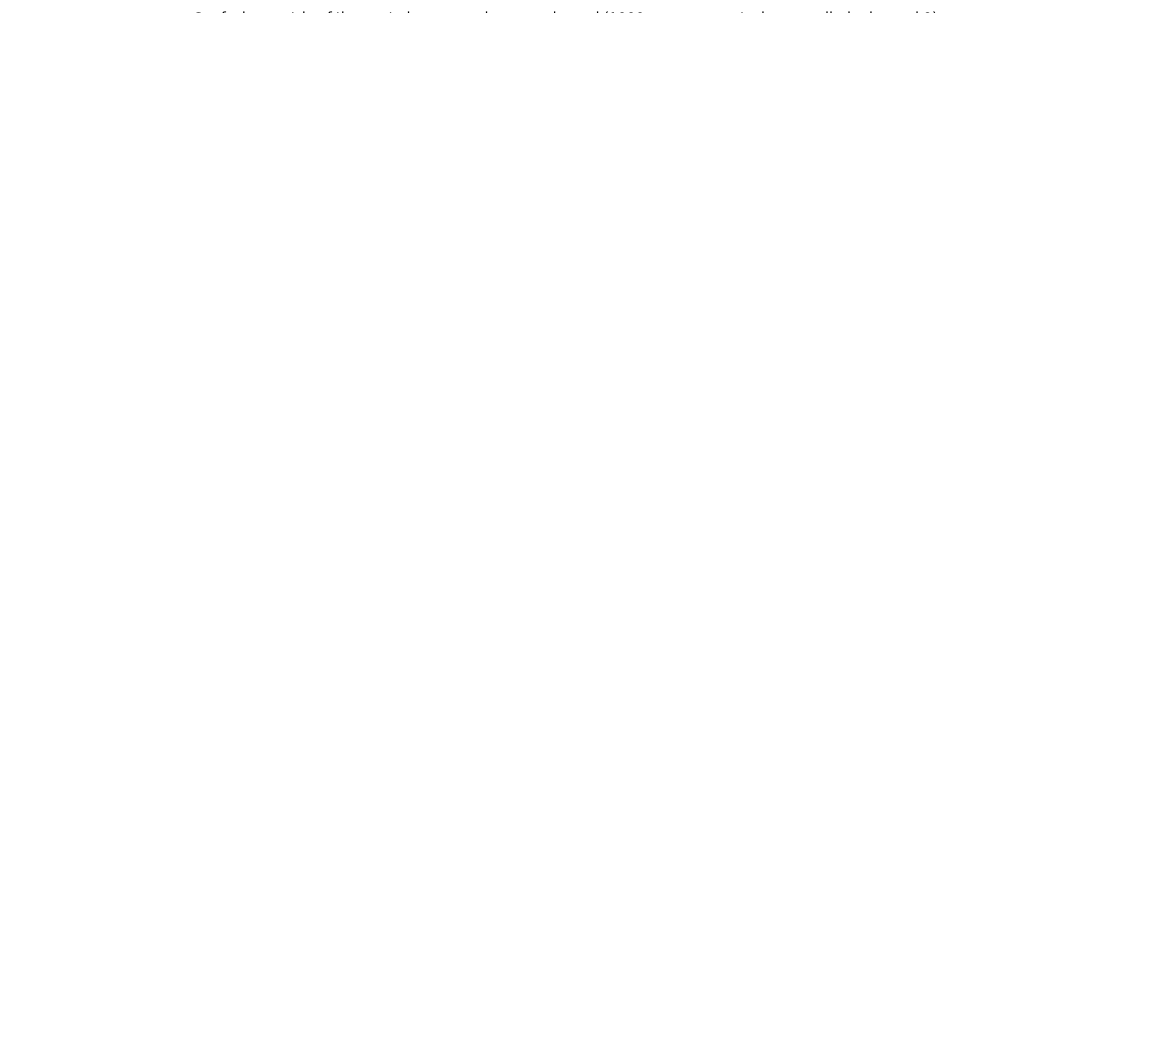

In [8]:
from matplotlib.patches import Rectangle
from sklearn.metrics import confusion_matrix


# Confusion matrix of the next-phrase readout (model trained by the activation cell above) at the prediction points
# of the test songs, normalized per true class (diagonal: recall of each class), the row and column of CLASS framed
#
# To change the study: set these options at the top of the activation cell above, then run the two cells again
#   VARIANT = "next_phrase_calls_leak"  leak rate of each reservoir in the search
#             "next_phrase_calls"       no leak (leaky_rate = 1)
#             (both: the 13 MFCC, reservoir on the whole song, the calls are phrases too (class "call"))
#   MODEL = "mean_hag", "var_hag", "random_ee", "random_ei"  (SIZE = 500 or 1000)
#           "mean_hag+random_ee", "mean_hag+random_ei", "var_hag+random_ee", "var_hag+random_ei"  (SIZE = 1000)
#   (default: var_hag+random_ei, 1000 neurons, next_phrase_calls_leak: the best model on the test songs)
#   SEED = 0, 1, ...  (matrices of the reservoir and HAG's random choices)
CLASS = "END"  # class framed: a phrase label ("A", "B1", ..., "Z", "call" with the calls) or "END"

if "readout" not in globals():
    raise NameError("Run the activation cell first: it trains the reservoir and the next-phrase readout")
if CLASS not in classes:
    raise ValueError(f"Unknown class {CLASS!r}, one of {list(classes)}")
true = np.concatenate([songs[w]["next"] for w in test_songs])
predicted = classes[readout.run(np.vstack([test_states[w] for w in test_songs])).argmax(axis=1)]
counts = confusion_matrix(true.astype(str), predicted.astype(str), labels=classes.astype(str))
rates = counts / np.maximum(counts.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(12, 10.5))
image = ax.imshow(rates, cmap="Blues", vmin=0, vmax=1)
for i in range(len(classes)):
    for j in range(len(classes)):
        if counts[i, j]:
            ax.text(j, i, f"{100 * rates[i, j]:.0f}", ha="center", va="center", fontsize=6,
                    color="white" if rates[i, j] > 0.5 else "black")
k = list(classes).index(CLASS)
ax.add_patch(Rectangle((-0.5, k - 0.5), len(classes), 1, fill=False, edgecolor="red", linewidth=1.5))
ax.add_patch(Rectangle((k - 0.5, -0.5), 1, len(classes), fill=False, edgecolor="red", linewidth=1.5))
ax.set_xticks(range(len(classes)), classes, rotation=90)
ax.set_yticks(range(len(classes)), [f"{label} ({n})" for label, n in zip(classes, counts.sum(axis=1))])
ax.tick_params(length=0, pad=16)
ax.tick_params(axis="x", pad=22)
for k, label in enumerate(classes):  # the color of each phrase, between its labels and the matrix
    ax.add_patch(Rectangle((-1.15, k - 0.35), 0.5, 0.7, color=colors.get(label, "grey"), clip_on=False))
    ax.add_patch(Rectangle((k - 0.35, len(classes) - 0.35), 0.7, 0.5, color=colors.get(label, "grey"), clip_on=False))
ax.set_xlabel("predicted next phrase")
ax.set_ylabel("true next phrase (number of test points)")
ax.set_title(f"Confusion matrix of the next phrase, {MODEL} ({SIZE} neurons, {VARIANT}, seed {SEED})\ntest songs: "
             f"% of each true class (accuracy {np.mean(predicted == true):.1%}, {CLASS} framed)", fontsize=10)
fig.colorbar(image, ax=ax, fraction=0.046, format=lambda x, _: f"{x:.0%}")
plt.tight_layout()
plt.show()

## Espace des phrases (MFCC)

### ACP, UMAP et t-SNE des phrases en 3D

MFCC de chaque phrase (cris et TRASH compris, SIL ignorés), moyennés sur ses trames, standardisés puis réduits à 3 dimensions par ACP, UMAP et t-SNE (les 13 MFCC sans plancher de la phrase suivante, mis à l'échelle sur les chants d'entraînement). Graphes interactifs (plotly) : chacun se tourne et se zoome à la souris ; un clic sur une phrase de la légende la masque dans les trois, un double clic n'affiche qu'elle. Un clic sur un point joue son extrait (avec `CONTEXT` secondes autour) et affiche sous les graphes la séquence des phrases de son chant (la phrase cliquée encadrée) et le spectrogramme de la phrase avec ses `NEIGHBORS` voisines de chaque côté, leurs étiquettes en haut (second lecteur : la phrase et ses voisines). Indépendant des cellules précédentes.

### Trajectoire d'un chant dans l'espace UMAP (ou t-SNE)

Le chant choisi dans la première liste (des chants de `SPLIT` de la cellule précédente, à exécuter d'abord ; `SONG` au départ) parcouru trame par trame dans l'espace UMAP 3D des phrases : les MFCC moyennés sur une fenêtre glissante de `WINDOW` secondes, placés dans l'espace des phrases choisi dans la seconde liste (`EMBEDDING` au départ) : projetés par l'UMAP des phrases (`umap_reducer.transform`) ou, t-SNE n'ayant pas de projection de nouveaux points, à la moyenne des positions t-SNE des 10 phrases les plus proches en MFCC (pondérée par l'inverse de la distance), puis lissés le long du temps (filtre gaussien d'écart-type `SMOOTH` secondes). La courbe prend la couleur de la phrase en cours (gris fin dans les silences), avec l'étiquette de chaque phrase et le début et la fin du chant marqués ; en fond, le nuage des phrases de la cellule précédente. En dessous, le chant : son spectrogramme avec ses phrases et un lecteur ; pendant l'écoute, la sphère rouge suit sur la trajectoire la position du curseur (un clic sur le spectrogramme joue le chant à partir de là). La vue peut être tournée et zoomée pendant l'écoute (la sphère s'arrête le temps du geste).

In [10]:
import base64
import io

import ipywidgets as widgets
import librosa
import librosa.display
import numpy as np
import plotly.graph_objects as go
import soundfile as sf
from IPython.display import display
from matplotlib.colors import to_hex, to_rgb
from matplotlib.figure import Figure
from matplotlib.ticker import FormatStrFormatter
from scipy.ndimage import gaussian_filter1d
from sklearn.neighbors import NearestNeighbors

SONG = None  # song shown first (a song of SPLIT, cell above), None for the first one; then chosen in the dropdown
EMBEDDING = "UMAP"  # space of the phrases shown first (cell above): "UMAP" or "t-SNE"; then chosen in the dropdown
WINDOW = 0.15  # s, MFCC averaged over a sliding window of this duration (the phrases: their mean MFCC)
SMOOTH = 0.05  # s, standard deviation of the Gaussian smoothing of the trajectory along time

if "umap_reducer" not in globals() or "SpectrogramPlayer" not in globals():
    raise NameError("Run the cell above first: it learns the UMAP of the phrases and defines the player")


def show_trajectory(change=None):
    """The trajectory of the chosen song in the chosen space of the phrases, its spectrogram and its player below."""
    wave, embedding = song_choice.value, embedding_choice.value
    phrases = phrases_of[wave]

    # mean MFCC over a sliding window centered on each frame of the sung part, placed in the space of the phrases: by
    # the UMAP of the phrases (umap_reducer.transform), or, t-SNE having no transform, at the mean of the positions of
    # the 10 phrases nearest in the space of the MFCC, weighted by the inverse of their distance
    song_mfcc = mfcc_songs[wave]["mfcc"][:, :13]
    first_frame = int(phrases[0][0] / mfcc_frame)
    frames = np.arange(first_frame, min(int(phrases[-1][1] / mfcc_frame) + 1, len(song_mfcc)))
    half = max(int(round(WINDOW / mfcc_frame)) // 2, 0)
    low, high = np.maximum(frames - half, 0), np.minimum(frames + half + 1, len(song_mfcc))
    sums = np.vstack([np.zeros((1, song_mfcc.shape[1])), np.cumsum(song_mfcc, axis=0)])
    windows = mfcc_scaler.transform((sums[high] - sums[low]) / (high - low)[:, None])
    if embedding == "UMAP":
        trajectory = umap_reducer.transform(windows)
    else:
        distances, nearest = NearestNeighbors(n_neighbors=10).fit(X).kneighbors(windows)
        weights = 1 / np.maximum(distances, 1e-9)
        trajectory = (embeddings[embedding][nearest] * weights[:, :, None]).sum(axis=1) / weights.sum(axis=1)[:, None]
    trajectory = gaussian_filter1d(trajectory, sigma=SMOOTH / mfcc_frame, axis=0)
    times = frames * mfcc_frame

    # phrase of each frame (None in the silences between the phrases), and the runs of frames of the same phrase
    current = [None] * len(frames)
    for k, (start, end, _) in enumerate(phrases):
        for f in np.flatnonzero((times >= start) & (times < end)):
            current[f] = k
    runs = []  # (phrase index or None, first frame, end frame)
    for f, k in enumerate(current):
        if runs and runs[-1][0] == k:
            runs[-1] = (k, runs[-1][1], f + 1)
        else:
            runs.append((k, f, f + 1))

    fig = go.FigureWidget()
    cloud = embeddings[embedding]
    for label in sorted(set(phrase_labels)):  # the phrases of the cell above, faded
        mask = phrase_labels == label
        fig.add_trace(go.Scatter3d(x=cloud[mask, 0], y=cloud[mask, 1], z=cloud[mask, 2], mode="markers", name=label,
                                   legendgroup=label, hoverinfo="skip",
                                   marker=dict(size=2, color=to_hex(phrase_colors.get(label, "grey")), opacity=0.12)))
    for k, f0, f1 in runs:  # the trajectory, a segment per run (with the first point of the next one, for continuity)
        segment = trajectory[f0:min(f1 + 1, len(trajectory))]
        label = phrases[k][2] if k is not None else None
        fig.add_trace(go.Scatter3d(
            x=segment[:, 0], y=segment[:, 1], z=segment[:, 2], mode="lines", showlegend=False, hoverinfo="text",
            text=[f"{label or 'silence'}, {t:.2f} s" for t in times[f0:f0 + len(segment)]],
            line=dict(width=7 if label else 2, color=to_hex(phrase_colors.get(label, "grey")) if label else "#9a9a9a")))
    middles = [(k, (f0 + f1) // 2) for k, f0, f1 in runs if k is not None and phrases[k][1] - phrases[k][0] >= 0.2]
    fig.add_trace(go.Scatter3d(  # the label of each phrase of 0.2 s or more, at the middle of its run
        x=trajectory[[m for _, m in middles], 0], y=trajectory[[m for _, m in middles], 1],
        z=trajectory[[m for _, m in middles], 2], mode="text", showlegend=False, hoverinfo="skip",
        text=[phrases[k][2] for k, _ in middles], textfont=dict(size=14, color="#1a1a1a")))
    for f, name, color, symbol in ((0, "start", "#2e7d32", "diamond"), (len(trajectory) - 1, "end", "black", "square")):
        fig.add_trace(go.Scatter3d(x=[trajectory[f, 0]], y=[trajectory[f, 1]], z=[trajectory[f, 2]], mode="markers",
                                   name=name, marker=dict(size=7, color=color, symbol=symbol)))
    playback = len(fig.data)  # (index of the trace of the position of the playback)
    fig.add_trace(go.Scatter3d(x=[trajectory[0, 0]], y=[trajectory[0, 1]], z=[trajectory[0, 2]], mode="markers",
                               name="playback",
                               marker=dict(size=11, color="#e53935", line=dict(width=2, color="white"))))
    axis = dict(showticklabels=False, title="")
    fig.update_scenes(xaxis=axis, yaxis=axis, zaxis=axis,
                      camera=dict(eye=dict(x=0.95, y=0.95, z=0.7)))  # (closer than plotly's default)
    fig.update_layout(width=WIDTH, height=750, margin=dict(l=0, r=0, t=50, b=0),
                      legend=dict(itemsizing="constant", font_size=10),
                      title=f"{wave}: trajectory in the {embedding} of the phrases ({len(phrases)} phrases, MFCC over "
                            f"{WINDOW} s, smoothed over {SMOOTH} s)")

    # the song below: its spectrogram with its phrases (a figure of its own, not pyplot's current one) and a player,
    # the position of the playback shown on the trajectory
    rate = sf.info(wav_paths[wave]).samplerate
    t0 = max(phrases[0][0] - 0.3, 0)
    audio, _ = sf.read(wav_paths[wave], start=int(t0 * rate), stop=int((phrases[-1][1] + 0.3) * rate),
                       dtype="float32", always_2d=True)
    audio = audio.mean(axis=1)
    t1 = t0 + len(audio) / rate
    fig_spec = Figure(figsize=(WIDTH / 100, 3))
    ax = fig_spec.subplots()
    fig_spec.subplots_adjust(left=0.05, right=0.99, top=0.97, bottom=0.17)
    S_song = librosa.amplitude_to_db(np.abs(librosa.stft(audio, n_fft=1024, hop_length=256)), ref=np.max)
    librosa.display.specshow(S_song, sr=rate, hop_length=256, x_axis="time", y_axis="hz", ax=ax, cmap="magma",
                             x_coords=t0 + np.arange(S_song.shape[1]) * 256 / rate)
    ax.set_ylim(0, 10000)
    for p_start, p_end, p_label in phrases:  # the phrases on a band at the top (the label of the wide ones)
        ax.axvspan(p_start, p_end, ymin=0.9, ymax=1, color=phrase_colors.get(p_label, "grey"))
        if p_end - p_start > 0.01 * (t1 - t0):
            dark = np.dot(to_rgb(phrase_colors.get(p_label, "grey")), [0.299, 0.587, 0.114]) < 0.5  # (white label)
            ax.text((p_start + p_end) / 2, 9500, p_label, ha="center", va="center", fontsize=8,
                    color="white" if dark else "black")
    ax.set_xlim(t0, t1)
    ax.xaxis.set_major_formatter(FormatStrFormatter("%.0f"))
    ax.set_xlabel("time in the song (s)")
    image, sound = io.BytesIO(), io.BytesIO()
    fig_spec.savefig(image, format="png", dpi=100)
    sf.write(sound, audio, rate, format="WAV", subtype="PCM_16")
    player = SpectrogramPlayer(image="data:image/png;base64," + base64.b64encode(image.getvalue()).decode(),
                               audio="data:audio/wav;base64," + base64.b64encode(sound.getvalue()).decode(),
                               t0=t0, t1=t1, left=ax.get_position().x0, right=ax.get_position().x1, phrase=[t0, t1],
                               buttons=["song"])

    def follow(change):
        """The position of the playback on the trajectory (the frame of its time, within the sung part)."""
        f = int(np.clip(round(change["new"] / mfcc_frame) - first_frame, 0, len(trajectory) - 1))
        with fig.batch_update():
            fig.data[playback].x, fig.data[playback].y, fig.data[playback].z = (
                [trajectory[f, 0]], [trajectory[f, 1]], [trajectory[f, 2]])

    player.observe(follow, names="position")
    trajectory_view.children = [fig, player]


song_choice = widgets.Dropdown(options=[(f"{w} ({len(phrases_of[w])} phrases)", w) for w in phrase_waves],
                               value=SONG or phrase_waves[0], description="song", layout=widgets.Layout(width="560px"))
embedding_choice = widgets.Dropdown(options=list(embeddings), value=EMBEDDING, description="space",
                                    layout=widgets.Layout(width="220px"))
trajectory_view = widgets.VBox()
for choice in (song_choice, embedding_choice):
    choice.observe(show_trajectory, names="value")
show_trajectory()
display(widgets.VBox([widgets.HBox([song_choice, embedding_choice]), trajectory_view]))

### Phrases atypiques (outliers)

Phrases de tous les chants dont l'étiquette ne correspond pas à leur voisinage, avec des critères très stricts : leurs MFCC moyennés (comme ci-dessus) réduits en 3D par UMAP et par t-SNE (mêmes réglages), une phrase est retenue si, **dans les deux espaces**, aucune de ses `K` plus proches voisines n'a son étiquette, la phrase de son étiquette la plus proche est plus loin que pour `PERCENTILE` % des phrases, et au moins `MIN_OTHER` de ses voisines ont une même autre étiquette (celle à laquelle elle ressemble).

Le premier tableau montre les chants dont les phrases ressemblent rarement à leur étiquette (moins de la moitié) : leurs annotations semblent décalées dans le temps, et le décalage qui accorde le mieux leurs étiquettes à un kNN des MFCC des autres chants est estimé. Le second liste les outliers (en gris, à la fin, ceux de ces chants) : un clic sur une ligne affiche et joue l'outlier comme dans les graphes 3D (à exécuter d'abord), le bouton ♪ d'une étiquette (la sienne ou celles auxquelles il ressemble) une phrase typique de cette étiquette, pour comparer (la suivante des `TYPICAL` plus typiques à chaque clic). La case de chaque outlier le valide (son étiquette est fausse) ; le bouton au-dessus du tableau copie la liste des outliers validés (chant, phrase, début, fin, étiquette, étiquettes auxquelles il ressemble), à coller ici pour corriger les annotations. Les cases cochées sont gardées quand la cellule est relancée. Dans les graphes, les outliers sont marqués (losanges : ceux des chants suspects), et un clic sur une phrase (outlier ou non) l'affiche et la joue sous le tableau. UMAP et t-SNE des 12 890 phrases : une minute environ.

In [11]:
from collections import Counter

import anywidget
import ipywidgets as widgets
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import traitlets
import umap
from IPython.display import display
from matplotlib.colors import to_hex, to_rgb
from plotly.subplots import make_subplots
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.preprocessing import StandardScaler

K = 10  # neighbors of each phrase in the 3D spaces
MIN_OTHER = 8  # neighbors of a single other label, at least
PERCENTILE = 99  # nearest phrase of the same label further than for this percentage of the phrases
SHIFTS = np.round(np.arange(-4, 1.01, 0.05), 2)  # s, time shifts of the annotations tried for the suspicious songs
TYPICAL = 10  # typical phrases of each label, played in turn by the clicks on the label in the table

if "show_phrase" not in globals():
    raise NameError("Run the cell of the 3D graphs first: it defines the display of a phrase")

# the phrases of all the songs (TRASH included): their mean MFCC (as in the 3D graphs), their UMAP and t-SNE (the same
# settings)
all_waves = mfcc_train_songs + mfcc_test_songs
all_phrases = {w: song_phrases(annotations, w, ("SIL",)) for w in all_waves}
info = [(w, j) for w in all_waves for j in range(len(all_phrases[w]))]  # (song, phrase index) of each point


def mean_mfcc(wave, shift=0.0):
    """Mean MFCC of each phrase of the song, its annotation times shifted by shift seconds."""
    mfcc = mfcc_songs[wave]["mfcc"][:, :13]
    means = []
    for start, end, _ in all_phrases[wave]:
        f0 = int(np.clip(np.floor((start + shift) / mfcc_frame), 0, len(mfcc) - 1))
        f1 = int(np.clip(np.floor((end + shift) / mfcc_frame) + 1, f0 + 1, len(mfcc)))
        means.append(mfcc[f0:f1].mean(axis=0))
    return np.array(means)


all_scaler = StandardScaler()
X_all = all_scaler.fit_transform(np.vstack([mean_mfcc(w) for w in all_waves]))
all_labels = np.array([all_phrases[w][j][2] for w, j in info])
spaces = {"UMAP": umap.UMAP(n_components=3, n_neighbors=15, min_dist=0.1, random_state=0,
                           n_jobs=1).fit_transform(X_all),
          "t-SNE": TSNE(n_components=3, perplexity=30, init="pca", random_state=0).fit_transform(X_all)}

# outliers: in each space, no phrase of their label among their K nearest neighbors, the nearest phrase of their label
# further than for PERCENTILE % of the phrases, and at least MIN_OTHER neighbors of a single other label (the label
# they sound like); kept when they are outliers in both spaces
flags, sounds_like = {}, {}
for name, Y in spaces.items():
    nearest = NearestNeighbors(n_neighbors=K + 1).fit(Y).kneighbors(Y)[1][:, 1:]  # (without the phrase itself)
    to_same = np.full(len(Y), np.inf)
    for label in np.unique(all_labels):
        idx = np.flatnonzero(all_labels == label)
        if len(idx) > 1:
            to_same[idx] = NearestNeighbors(n_neighbors=2).fit(Y[idx]).kneighbors(Y[idx])[0][:, 1]
    majority = [Counter(all_labels[n]).most_common(1)[0] for n in nearest]
    sounds_like[name] = np.array([label for label, _ in majority])
    flags[name] = ((all_labels[nearest] != all_labels[:, None]).all(axis=1)
                   & (to_same > np.percentile(to_same[np.isfinite(to_same)], PERCENTILE))
                   & np.array([count >= MIN_OTHER for _, count in majority]))
outlier = flags["UMAP"] & flags["t-SNE"]

# songs whose phrases rarely sound like their label (their neighbors in the UMAP): their annotations shifted in time?
# The shift maximizing the agreement with the labels of a kNN of the mean MFCC of the phrases of the other songs
agreement = pd.Series(sounds_like["UMAP"] == all_labels).groupby([w for w, _ in info]).mean()
outliers_per_song = pd.Series(outlier).groupby([w for w, _ in info]).sum()
suspicious = list(agreement[agreement < 0.5].index)
others = [w for w in all_waves if w not in suspicious]
knn = KNeighborsClassifier(n_neighbors=10).fit(
    all_scaler.transform(np.vstack([mean_mfcc(w) for w in others])),
    np.concatenate([[label for _, _, label in all_phrases[w]] for w in others]))
rows, best_shift = [], {}  # best_shift: estimated shift of the annotations of each suspicious song (s)
for w in suspicious:
    labels = np.array([label for _, _, label in all_phrases[w]])
    accuracy = [np.mean(knn.predict(all_scaler.transform(mean_mfcc(w, shift))) == labels) for shift in SHIFTS]
    best = int(np.argmax(accuracy))
    best_shift[w] = float(SHIFTS[best])
    rows.append({"song": w, "split": "train" if w in set(mfcc_train_songs) else "test", "phrases": len(labels),
                 "sound like their label": agreement[w], "outliers": outliers_per_song[w],
                 "kNN agreement": accuracy[list(SHIFTS).index(0)], "best shift of the annotations (s)": SHIFTS[best],
                 "kNN agreement after the shift": accuracy[best]})
print(f"{outlier.sum()} outliers among {len(info)} phrases of {len(all_waves)} songs (UMAP only "
      f"{(flags['UMAP'] & ~outlier).sum()}, t-SNE only {(flags['t-SNE'] & ~outlier).sum()}); phrases sounding like "
      f"their label: {agreement.mean():.0%} per song on average, less than 50 % in {len(suspicious)} songs")
if rows:
    display(pd.DataFrame(rows).style.format(
        {"sound like their label": "{:.0%}", "kNN agreement": "{:.0%}", "kNN agreement after the shift": "{:.0%}",
         "best shift of the annotations (s)": "{:+.2f}"}, precision=2).hide(axis="index")
            .set_caption("Songs whose phrases rarely sound like their label (annotations shifted in time?)"))

# (the outliers of the suspicious songs last)
outlier_index = np.array(sorted(np.flatnonzero(outlier),
                                key=lambda k: (info[k][0] in suspicious, info[k][0], info[k][1])))
suspicious_point = np.isin([w for w, _ in info], suspicious)

# typical phrases of each label, to compare the outliers with: the phrases of the label nearest to the mean of its
# phrases in the space of the mean MFCC (outliers and phrases of the suspicious songs excepted)
typical = {}
for label in np.unique(all_labels):
    idx = np.flatnonzero(~outlier & ~suspicious_point & (all_labels == label))
    typical[label] = idx[np.argsort(np.linalg.norm(X_all[idx] - X_all[idx].mean(axis=0), axis=1))][:TYPICAL]
typical_turn = Counter()  # typical phrases of each label already played


class ClickableTable(anywidget.AnyWidget):
    """Table (scrolling, its header fixed) whose rows can be clicked, and the button of the cells which have one: each
    click sends back [row, column, "row" or "button", a number of its own] in clicked. With copy_lines (a line of text
    per row), a check box per row (the checked rows in checked) and a button copying copy_header and the lines of the
    checked rows (shown below it too, if the clipboard is not available)."""
    _esm = """
    function render({ model, el }) {
      const checkable = model.get("copy_lines").length > 0;
      el.innerHTML = `
        <style>.clickable-table tbody tr:hover td { filter: brightness(0.9); }</style>
        <div style="font:12px sans-serif;color:#777;margin:4px 0">${model.get("caption")}</div>
        <div style="font:12px sans-serif;margin:4px 0;align-items:center;gap:8px;
                    display:${checkable ? "flex" : "none"}">
          <button class="copy" style="font:12px sans-serif;cursor:pointer"></button>
          <span class="copied" style="color:#777"></span></div>
        <textarea class="copy-text" readonly style="display:none;width:900px;max-width:100%;height:110px;
                                                    font:11px monospace;margin:4px 0"></textarea>
        <div style="max-height:420px;overflow:auto;display:inline-block;border:1px solid #ddd">
          <table class="clickable-table" style="border-collapse:collapse;font:12px sans-serif">
            <thead></thead><tbody></tbody></table></div>`;
      const head = el.querySelector("thead"), body = el.querySelector("tbody");
      const th = (c) => `<th style="position:sticky;top:0;background:#f3f3f3;padding:4px 8px;text-align:left;
                                    border-bottom:1px solid #ccc;z-index:1">${c}</th>`;
      head.innerHTML = "<tr>" + (checkable ? th("validated") : "") + model.get("columns").map(th).join("") + "</tr>";
      const checked = new Set(model.get("checked"));
      const copyButton = el.querySelector(".copy"), copied = el.querySelector(".copied");
      const copyText = el.querySelector(".copy-text");
      const count = () => { copyButton.textContent = `\u29c9 copy the ${checked.size} validated rows`; };
      count();
      copyButton.addEventListener("click", async () => {
        const lines = [...checked].sort((a, b) => a - b).map((r) => model.get("copy_lines")[r]);
        copyText.value = [model.get("copy_header"), ...lines].join("\\n");
        copyText.style.display = "block";
        try {
          await navigator.clipboard.writeText(copyText.value);
          copied.textContent = `copied (${lines.length} rows)`;
        } catch (error) {  // (no clipboard: the selected text, to copy by hand if execCommand fails too)
          copyText.select();
          copied.textContent = document.execCommand("copy") ? `copied (${lines.length} rows)`
                                                            : "copy the text below";
        }
      });
      let selected = null;
      const send = (r, c, kind, element) => {
        if (selected) selected.style.outline = "";
        element.style.outline = "2px solid #e53935";
        element.style.outlineOffset = "-2px";
        selected = element;
        model.set("clicked", [r, c, kind, Date.now() + Math.random()]);  // (always a change, whatever the view)
        model.save_changes();
      };
      model.get("rows").forEach((row, r) => {
        const tr = body.insertRow();
        tr.style.cursor = "pointer";
        tr.title = model.get("row_title");
        if (checkable) {
          const td = tr.insertCell(), box = document.createElement("input");
          td.style.cssText = "padding:3px 8px;border-bottom:1px solid #eee;text-align:center";
          box.type = "checkbox";
          box.checked = checked.has(r);
          box.style.cursor = "pointer";
          box.addEventListener("click", (e) => e.stopPropagation());  // (not a click on the row)
          td.addEventListener("click", (e) => e.stopPropagation());
          box.addEventListener("change", () => {
            if (box.checked) checked.add(r); else checked.delete(r);
            model.set("checked", [...checked].sort((a, b) => a - b));
            model.save_changes();
            count();
          });
          td.appendChild(box);
        }
        row.forEach((cell, c) => {
          const td = tr.insertCell();
          td.textContent = cell.text;
          td.style.cssText = "padding:3px 8px;border-bottom:1px solid #eee;white-space:nowrap;" + (cell.style || "");
          td.addEventListener("click", () => send(r, c, "row", tr));
          if (cell.button) {
            const button = document.createElement("button");
            button.textContent = cell.button;
            button.title = cell.button_title || "";
            button.style.cssText = "margin-left:6px;font:11px sans-serif;padding:0 5px;cursor:pointer";
            button.addEventListener("click", (e) => { e.stopPropagation(); send(r, c, "button", button); });
            td.appendChild(button);
          }
        });
      });
    }
    export default { render };
    """
    caption = traitlets.Unicode("").tag(sync=True)
    columns = traitlets.List([]).tag(sync=True)
    rows = traitlets.List([]).tag(sync=True)  # rows of cells {text, style, button (its text), button_title}
    row_title = traitlets.Unicode("").tag(sync=True)  # tooltip of the rows
    clicked = traitlets.List([]).tag(sync=True)  # last click: [row, column, "row" or "button", a number of its own]
    copy_header = traitlets.Unicode("").tag(sync=True)  # first line of the copied text
    copy_lines = traitlets.List([]).tag(sync=True)  # line of each row in the copied text (none: no check boxes)
    checked = traitlets.List([]).tag(sync=True)  # checked rows


def label_cell(label):
    """Cell of a label, on its color, with a button playing a typical phrase of the label."""
    r, g, b = to_rgb(phrase_colors.get(label, "grey"))
    text_color = "#1a1a1a" if 0.299 * r + 0.587 * g + 0.114 * b > 0.6 else "white"  # (readable on the color)
    return {"text": str(label), "style": f"background:{to_hex((r, g, b))};color:{text_color};font-weight:bold",
            "button": "\u266a typical", "button_title": f"a typical {label} phrase (the next one at each click)"}


# validated outliers: (song, phrase index) of the checked rows, kept when the cell is run again
validated_outliers = globals().get("validated_outliers", set())
rows, copy_lines = [], []
for k in outlier_index:
    wave, j = info[k]
    start, end, label = all_phrases[wave][j]
    copy_lines.append("\t".join([wave, str(j + 1), f"{start:.3f}", f"{end:.3f}", label, sounds_like["UMAP"][k],
                                 sounds_like["t-SNE"][k]]))
    style = "color:#9a9a9a" if suspicious_point[k] else ""
    plain = [wave, "train" if wave in set(mfcc_train_songs) else "test", j + 1, f"{start:.2f}", f"{end - start:.2f}"]
    rows.append([{"text": str(text), "style": style} for text in plain]
                + [label_cell(lab) for lab in (label, sounds_like["UMAP"][k], sounds_like["t-SNE"][k])]
                + [{"text": "yes" if suspicious_point[k] else "", "style": style}])
outlier_table = ClickableTable(
    columns=["song", "split", "phrase", "start (s)", "duration (s)", "label", "sounds like (UMAP)",
             "sounds like (t-SNE)", "suspicious song"],
    rows=rows, row_title="click: this outlier",
    caption=f"The {len(outlier_index)} outliers (in grey, at the end: those of the suspicious songs). Click a row to "
            "see and hear the outlier, the \u266a button of a label to see and hear a typical phrase of this label "
            f"(the next of its {TYPICAL} most typical ones at each click). Check the outliers whose label is wrong, "
            "and copy their list with the button.",
    copy_header="\t".join(["song", "phrase", "start (s)", "end (s)", "label", "sounds like (UMAP)",
                           "sounds like (t-SNE)"]),
    copy_lines=copy_lines, checked=[r for r, k in enumerate(outlier_index) if info[k] in validated_outliers])


def check_outliers(change):
    """The checked rows of the table: the validated outliers."""
    validated_outliers.difference_update(info[k] for k in outlier_index)
    validated_outliers.update(info[outlier_index[r]] for r in change["new"])


# the two spaces: the phrases faded, the outliers marked (diamonds: those of the suspicious songs); a click on a
# phrase (an outlier or not) shows and plays it below the table
fig_out = go.FigureWidget(make_subplots(rows=1, cols=len(spaces), specs=[[{"type": "scene"}] * len(spaces)],
                                        subplot_titles=list(spaces), horizontal_spacing=0.01))
for col, (name, Y) in enumerate(spaces.items(), start=1):
    for label in sorted(set(all_labels)):
        index = np.flatnonzero(all_labels == label)
        fig_out.add_trace(go.Scatter3d(
            x=Y[index, 0], y=Y[index, 1], z=Y[index, 2], mode="markers", name=label, legendgroup=label,
            showlegend=col == 1, customdata=index, hoverinfo="text",
            text=[f"{label} (sounds like {sounds_like[name][k]}), phrase {info[k][1] + 1} of {info[k][0]}"
                  for k in index],
            marker=dict(size=4 if label == "TRASH" else 2, color=to_hex(phrase_colors.get(label, "grey")),
                        opacity=0.8 if label == "TRASH" else 0.2)),  # (TRASH: a few points)
            row=1, col=col)
    fig_out.add_trace(go.Scatter3d(
        x=Y[outlier_index, 0], y=Y[outlier_index, 1], z=Y[outlier_index, 2], mode="markers", name="outliers",
        legendgroup="outliers", showlegend=col == 1, customdata=outlier_index, hoverinfo="text",
        text=[f"{all_labels[k]} (sounds like {sounds_like[name][k]}), phrase {info[k][1] + 1} of {info[k][0]}"
              for k in outlier_index],
        marker=dict(size=6, color=[to_hex(phrase_colors.get(all_labels[k], "grey")) for k in outlier_index],
                    symbol=["diamond" if info[k][0] in suspicious else "circle" for k in outlier_index],
                    line=dict(width=2, color="#e53935"), opacity=1)),
        row=1, col=col)
axis = dict(showticklabels=False, title="")
fig_out.update_scenes(xaxis=axis, yaxis=axis, zaxis=axis)
fig_out.update_layout(width=WIDTH, height=750, margin=dict(l=0, r=0, t=60, b=0),
                      legend=dict(itemsizing="constant", font_size=10),
                      title=f"The {outlier.sum()} outliers of the {len(info)} phrases of all the songs "
                            "(click a phrase to listen)")
outlier_header = widgets.Output()
outlier_player = SpectrogramPlayer(layout=widgets.Layout(display="none"))


def show_point(k, title=None):
    """The phrase k (index in info), shown and played below the table."""
    wave, j = info[k]
    if title is None:
        title = (f"{'Outlier' if outlier[k] else 'Phrase'} {all_labels[k]}, sounds like {sounds_like['UMAP'][k]} "
                 f"(UMAP) and {sounds_like['t-SNE'][k]} (t-SNE)"
                 + (" (suspicious song)" if suspicious_point[k] else ""))
    show_phrase(wave, all_phrases[wave], j, outlier_header, outlier_player, title)


def click_phrase(trace, points, selector):
    if points.point_inds:
        show_point(int(trace.customdata[points.point_inds[0]]))


def click_cell(change):
    """A click in the table: on a row, its outlier; on the button of a label, a typical phrase of this label (the next
    one at each click)."""
    row, column, kind, _ = change["new"]
    k = outlier_index[row]
    if kind == "row":
        show_point(k)
        return
    label = {5: all_labels[k], 6: sounds_like["UMAP"][k], 7: sounds_like["t-SNE"][k]}[column]
    if len(typical[label]):
        n = typical_turn[label] % len(typical[label])
        typical_turn[label] += 1
        show_point(typical[label][n], f"Typical {label} phrase ({n + 1} / {len(typical[label])}, the nearest to the "
                                      f"mean of the {label} phrases first)")


for trace in fig_out.data:
    trace.on_click(click_phrase)
outlier_table.observe(click_cell, names="clicked")
outlier_table.observe(check_outliers, names="checked")
display(widgets.VBox([outlier_table, outlier_header, outlier_player, fig_out]))

89 outliers among 12981 phrases of 459 songs (UMAP only 26, t-SNE only 31); phrases sounding like their label: 97% per song on average, less than 50 % in 0 songs


### Chants aux annotations décalées

Les chants suspects de la cellule précédente (à exécuter d'abord), entiers : leurs annotations (bande du haut) et ces annotations décalées (bande du dessous), du décalage estimé au départ, réglable avec le curseur. Le lecteur joue le chant, le curseur suit la lecture.

Les annotations des 5 chants trouvés décalés (172, 290, 365, 418, 430) sont corrigées dans les fichiers d'annotations (décalages estimés en alignant les segments annotés sur l'énergie du chant, voir `canary.datasets.songs`) : ils ne sont plus suspects, mais restent dans la liste, avec leurs annotations corrigées (bande du haut) ; le curseur, à 0 au départ, les décale (à l'opposé de la correction : les annotations d'origine).

In [12]:
import base64
import io

import ipywidgets as widgets
import librosa
import librosa.display
import numpy as np
import soundfile as sf
from IPython.display import display
from matplotlib.colors import to_rgb
from matplotlib.figure import Figure
from matplotlib.ticker import FormatStrFormatter

if "best_shift" not in globals():
    raise NameError("Run the cell of the outliers first: it estimates the shifts of the annotations of the suspicious "
                    "songs")

# s, shifts of the songs whose annotation files are corrected (canary.datasets.songs): shown first,
# unshifted at first (the opposite shift: their original annotations); then the suspicious songs, at their estimated
# shift
CORRECTED = {"172_marron1_May_27_2016_38615584.wav": -0.810, "290_marron1_June_08_2016_25875641.wav": -0.990,
             "365_marron1_June_12_2016_43103084.wav": -1.715, "418_marron1_June_15_2016_49011949.wav": -1.980,
             "430_marron1_June_16_2016_28193589.wav": -1.380}
first_shift = {**{w: 0.0 for w in CORRECTED}, **best_shift}

def show_shifted_song():
    """The spectrogram of the whole chosen song, its annotations at the top and the shifted ones below, and a player."""
    wave = shifted_song_choice.value
    audio, rate = sf.read(wav_paths[wave], dtype="float32", always_2d=True)
    audio = audio.mean(axis=1)
    t1 = len(audio) / rate
    fig_song = Figure(figsize=(WIDTH / 100, 3.4))  # (a figure of its own, not pyplot's current one)
    ax = fig_song.subplots()
    fig_song.subplots_adjust(left=0.05, right=0.99, top=0.9, bottom=0.15)
    S_song = librosa.amplitude_to_db(np.abs(librosa.stft(audio, n_fft=1024, hop_length=256)), ref=np.max)
    librosa.display.specshow(S_song, sr=rate, hop_length=256, x_axis="time", y_axis="hz", ax=ax, cmap="magma")
    ax.set_ylim(0, 10000)
    shifted = [(max(start + shift_slider.value, 0.0), max(end + shift_slider.value, 0.01), label)
               for start, end, label in all_phrases[wave]]  # (kept within the song)
    for phrases, low in ((all_phrases[wave], 0.9), (shifted, 0.8)):  # two bands of the phrases at the top
        for p_start, p_end, p_label in phrases:
            ax.axvspan(p_start, p_end, ymin=low, ymax=low + 0.1, color=phrase_colors.get(p_label, "grey"))
            if p_end - p_start > 0.008 * t1:  # (the label of the wide ones)
                dark = np.dot(to_rgb(phrase_colors.get(p_label, "grey")), [0.299, 0.587, 0.114]) < 0.5
                ax.text((p_start + p_end) / 2, (low + 0.05) * 10000, p_label, ha="center", va="center", fontsize=7,
                        color="white" if dark else "black")
    ax.set_xlim(0, t1)
    ax.xaxis.set_major_formatter(FormatStrFormatter("%.0f"))
    ax.set_xlabel("time in the song (s)")
    corrected = f" (corrected in the files by {CORRECTED[wave]:+.3f} s)" if wave in CORRECTED else ""
    ax.set_title(f"{wave}: annotations{corrected} (top band) and annotations shifted by {shift_slider.value:+.3f} s "
                 "(band below)", fontsize=10, loc="left")
    image, sound = io.BytesIO(), io.BytesIO()
    fig_song.savefig(image, format="png", dpi=100)
    sf.write(sound, audio, rate, format="WAV", subtype="PCM_16")
    shifted_song_view.children = [SpectrogramPlayer(
        image="data:image/png;base64," + base64.b64encode(image.getvalue()).decode(),
        audio="data:audio/wav;base64," + base64.b64encode(sound.getvalue()).decode(),
        t0=0, t1=t1, left=ax.get_position().x0, right=ax.get_position().x1, phrase=[0, t1], buttons=["song"])]


def choose_shifted_song(change=None):
    """The chosen song, unshifted (corrected songs) or at its estimated shift."""
    if shift_slider.value != first_shift[shifted_song_choice.value]:
        shift_slider.value = first_shift[shifted_song_choice.value]  # (redraws)
    else:
        show_shifted_song()


if not suspicious:
    print("No suspicious song: the phrases of all the songs sound like their label (the corrected songs below)")
shifted_song_choice = widgets.Dropdown(
    options=[(f"{w} (corrected in the files by {s:+.3f} s)", w) for w, s in CORRECTED.items()]
            + [(f"{w} (suspicious, estimated shift {best_shift[w]:+.2f} s)", w) for w in suspicious],
    description="song", layout=widgets.Layout(width="560px"))
shift_slider = widgets.FloatSlider(min=SHIFTS[0], max=max(SHIFTS[-1], *(-s for s in CORRECTED.values())),
                                   step=0.005, description="shift (s)", continuous_update=False, readout_format="+.3f",
                                   layout=widgets.Layout(width="500px"))
shifted_song_view = widgets.VBox()
shifted_song_choice.observe(choose_shifted_song, names="value")
shift_slider.observe(lambda change: show_shifted_song(), names="value")
choose_shifted_song()
display(widgets.VBox([widgets.HBox([shifted_song_choice, shift_slider]), shifted_song_view]))

No suspicious song: the phrases of all the songs sound like their label (the corrected songs below)
